<img src="https://www.pucsp.br/sites/default/files/download/brasao-PUCSP-assinatura-principal-RGB.png" style="float:right;" width="150px">

# Ciências da Computação [》](https://www.pucsp.br/graduacao/ciencia-da-computacao)

## Inteligência Artificial

IA ML (Machine Learning, Aprendizagem de Máquina)

**Objetivo deste exercício: explorar a IA ML Cluster - IA não supervisionada. Mini Projeto em pares, escolher dados no Kaggle (dados diferentes por equipe) e experimentar/explorar um modelo de cluster como K-Means, AffinityPropagation, etc... publicar o notebook EDA no GitHub e subir o link do repo no MS Teams na atividade.**

**Fontes**

*   https://www.kaggle.com/
*   https://scikit-learn.org/stable/modules/clustering.html

**Dupla**

| Integrante | Nome | RA |
|---|---|---|
| Integrante 1 | Daniel Teles de Oliveira | RA00334427 |
| Integrante 2 | João Victor Torres Soares | RA00330701 |

## Atividades


- Aprendizado não supervisionado e clusterização
- Escolha do dataset e importação
- **EDA**: estrutura, dados ausentes, distribuições, outliers, relações bivariadas e correlação
- **Feature engineering** e padronização
- **PCA** (redução de dimensionalidade)
- Escolha do número de clusters (cotovelo, silhouette, Calinski-Harabasz e Davies-Bouldin)
- **Modelo base: K-Means**
- **Interpretação dos grupos** (perfis, boxplots, radar e gênero)
- **Comparação com outros modelos** (Hierárquico, GMM, DBSCAN, OPTICS, Affinity Propagation, Mean Shift, BIRCH e Espectral)
- K-Means com mais variáveis (idade) e estabilidade
- Conclusões


## 1. O que é Aprendizado Não Supervisionado e Clusterização?
No Aprendizado Não Supervisionado, os dados fornecidos ao algoritmo não possuem rótulos. O objetivo é encontrar estruturas ocultas, padrões ou agrupamentos naturais nos dados por conta própria.

A Clusterização é a técnica que consiste em dividir os dados em grupos de forma que pontos no mesmo grupo sejam o mais semelhantes possível entre si, e o mais diferentes possível dos pontos de outros grupos.

Neste projeto, o modelo base é o **K-Means**, que particiona os dados em $K$ clusters distintos, minimizando a variância dentro de cada grupo. Depois, comparamos o K-Means com outras famílias de algoritmos:

| Família | Algoritmos | Ideia central |
|---|---|---|
| Particionamento | K-Means, BIRCH | Centroides e distância |
| Hierárquica | Aglomerativo (Ward, Single) | Fusão sucessiva dos pontos mais próximos |
| Modelo probabilístico | Gaussian Mixture (GMM) | Cada cluster é uma gaussiana (atribuição "suave") |
| Densidade | DBSCAN, OPTICS | Regiões densas separadas por regiões esparsas; detectam ruído |
| Passagem de mensagens | Affinity Propagation | Pontos "elegem" exemplares; não exige $K$ |
| Deslocamento de moda | Mean Shift | Sobe o gradiente de densidade; não exige $K$ |
| Espectral | Spectral Clustering | Usa autovetores do grafo de vizinhança |

In [2]:
!pip install kagglehub -q #Instalação necessária para obter o DataFrame do Kaggle
import warnings
warnings.filterwarnings('ignore')

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.neighbors import NearestNeighbors
from sklearn.mixture import GaussianMixture
from sklearn.cluster import (KMeans, AgglomerativeClustering, DBSCAN, OPTICS,
                             AffinityPropagation, MeanShift, estimate_bandwidth,
                             Birch, SpectralClustering)
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## 2. Escolha do Dataset e Importação

O dataset selecionado foi o *Mall_Customers*, disponibilizado na plataforma Kaggle, que reúne informações demográficas e comportamentais de 200 clientes de um shopping center:

| Variável | Descrição |
|---|---|
| `CustomerID` | Identificador do cliente (não é informativo para o modelo) |
| `Gender` | Gênero |
| `Age` | Idade |
| `Annual Income (k$)` | Renda anual em milhares de dólares |
| `Spending Score (1-100)` | Pontuação de gastos atribuída pelo shopping (1 a 100) |

Visando garantir a reprodutibilidade do projeto, o arquivo `Mall_Customers.csv` é importado diretamente pela API do Kaggle, sem download e upload manual no Google Colab.

In [3]:
path = kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python")
caminho_csv = f"{path}/Mall_Customers.csv"

df = pd.read_csv(caminho_csv)

# Atalhos para os nomes longos das colunas
COL_INC = 'Annual Income (k$)'
COL_SPEND = 'Spending Score (1-100)'

print(f"Dimensões: {df.shape[0]} linhas x {df.shape[1]} colunas")
display(df.head())

Using Colab cache for faster access to the 'customer-segmentation-tutorial-in-python' dataset.
Dimensões: 200 linhas x 5 colunas


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 3. Análise Exploratória de Dados (EDA)

Nesta etapa ocorre a análise da estrutura do dataset, verificação de dados ausentes, duplicados e inválidos, investigação das distribuições e outliers, observação relações entre variáveis e medir correlações.

### 3.1 Estrutura do dataset

In [4]:
print("--- Informações do Dataset ---")
df.info()

print("\n--- Estatísticas descritivas ---")
display(df.describe(include='all').T)

--- Informações do Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

--- Estatísticas descritivas ---


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,200.0,NaN,NaN,NaN,100.5,57.879185,1.0,50.75,100.5,150.25,200.0
Gender,200,2,Female,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,200.0,NaN,NaN,NaN,38.85,13.969007,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,NaN,NaN,NaN,60.56,26.264721,15.0,41.5,61.5,78.0,137.0
Spending Score (1-100),200.0,NaN,NaN,NaN,50.2,25.823522,1.0,34.75,50.0,73.0,99.0


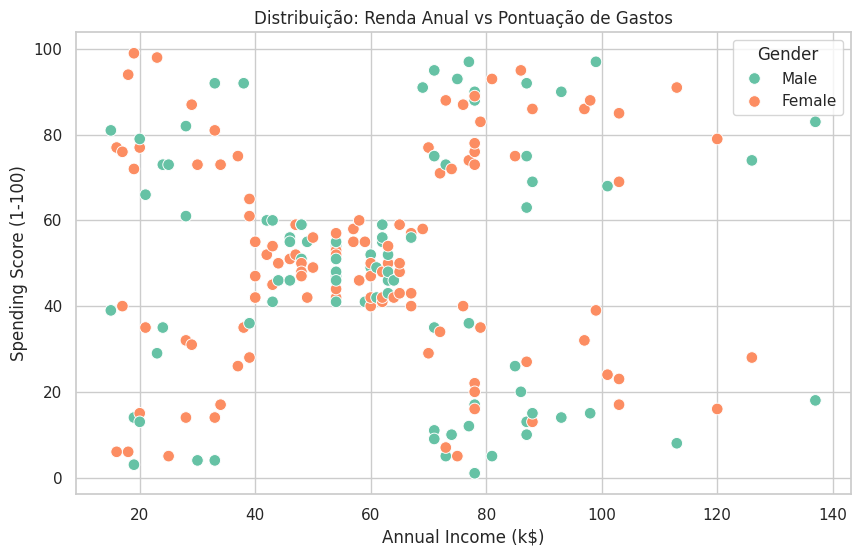

In [5]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x=COL_INC, y=COL_SPEND, hue='Gender', palette='Set2', s=70)
plt.title('Distribuição: Renda Anual vs Pontuação de Gastos')
plt.show()

### 3.2 Dados ausentes, duplicados e valores inválidos

Como os algoritmos são baseados em distâncias, um único valor ausente pode distorcer os centroides. Assim, esses valores são analisados para identificações e mitigações.

,ausentes,% ausentes
CustomerID,0,0.0
Gender,0,0.0
Age,0,0.0
Annual Income (k$),0,0.0
Spending Score (1-100),0,0.0


Linhas duplicadas (todas as colunas)      : 0
CustomerID duplicados                      : 0

--- Violações de regras de domínio ---
Age fora de [18, 100]              : 0
Renda <= 0                         : 0
Spending Score fora de [1, 100]    : 0
Gender fora de {Male, Female}      : 0


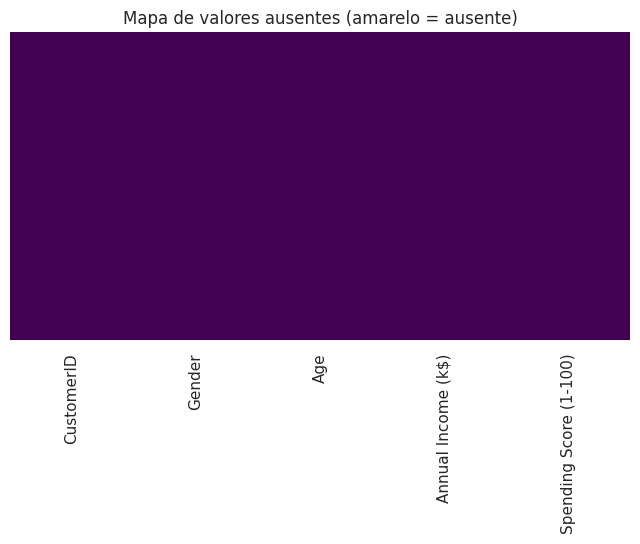

In [6]:
# 1) Dados ausentes
ausentes = pd.DataFrame({'ausentes': df.isnull().sum(),
                         '% ausentes': (df.isnull().mean() * 100).round(2)})
display(ausentes)

# 2) Duplicados
print("Linhas duplicadas (todas as colunas)      :", df.duplicated().sum())
print("CustomerID duplicados                      :", df['CustomerID'].duplicated().sum())

# 3) Valores inválidos (regras de domínio)
regras = {
    'Age fora de [18, 100]'            : ~df['Age'].between(18, 100),
    'Renda <= 0'                       : df[COL_INC] <= 0,
    'Spending Score fora de [1, 100]'  : ~df[COL_SPEND].between(1, 100),
    'Gender fora de {Male, Female}'    : ~df['Gender'].isin(['Male', 'Female']),
}
print("\n--- Violações de regras de domínio ---")
for regra, violacao in regras.items():
    print(f"{regra:35s}: {int(violacao.sum())}")

# 4) Mapa visual de ausentes
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis', ax=ax)
ax.set_title('Mapa de valores ausentes (amarelo = ausente)')
plt.show()

**Tratamento.** O dataset original está completo. Porémm, deixou-se o pipeline de tratamento pronto e **comparamos estratégias de imputação** simulando 8% de valores ausentes aleatórios (MCAR) e medindo o erro absoluto médio (MAE) contra o valor verdadeiro:

* **Mediana**: simples e robusta a outliers;
* **KNN (k=5)**: usa os vizinhos mais parecidos para estimar o valor.

Valores removidos na simulação:
 Age                       15
Annual Income (k$)        12
Spending Score (1-100)    12


,Mediana,KNN (k=5)
Age,11.60,13.21
Annual Income (k$),16.50,16.47
Spending Score (1-100),26.08,25.98


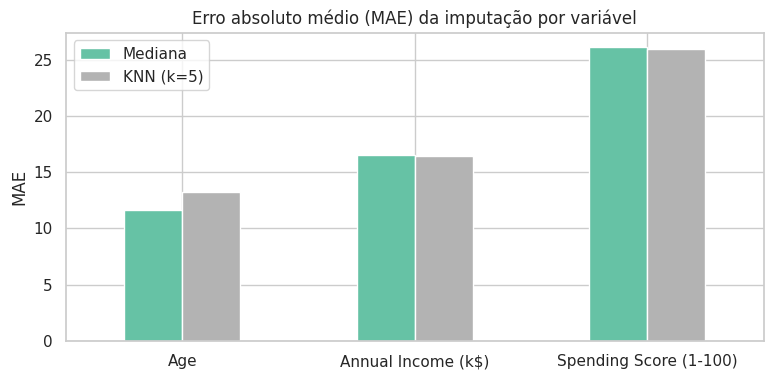

Ausentes após o tratamento: 0


In [7]:
def tratar_ausentes(dados):
    """Imputa numéricas com a mediana e categóricas com a moda."""
    dados = dados.copy()
    num = dados.select_dtypes(include='number').columns.drop('CustomerID', errors='ignore')
    cat = dados.select_dtypes(exclude='number').columns
    for c in num:
        if dados[c].isnull().any():
            dados[c] = dados[c].fillna(dados[c].median())
    for c in cat:
        if dados[c].isnull().any():
            dados[c] = dados[c].fillna(dados[c].mode()[0])
    return dados

# --- Simulação: removemos 8% dos valores e comparamos as imputações ---
rng = np.random.default_rng(SEED)
cols_num = ['Age', COL_INC, COL_SPEND]
mascara = pd.DataFrame(rng.random((len(df), len(cols_num))) < 0.08, columns=cols_num)
df_sim = df.copy()
for c in cols_num:
    df_sim.loc[mascara[c], c] = np.nan
print("Valores removidos na simulação:\n", df_sim[cols_num].isnull().sum().to_string())

imputadores = {'Mediana': SimpleImputer(strategy='median'),
               'KNN (k=5)': KNNImputer(n_neighbors=5)}
mae = {}
for nome, imp in imputadores.items():
    imputado = pd.DataFrame(imp.fit_transform(df_sim[cols_num]), columns=cols_num)
    erro = (imputado - df[cols_num]).abs().where(mascara)
    mae[nome] = erro.mean()
mae = pd.DataFrame(mae)
display(mae.round(2))

mae.plot(kind='bar', figsize=(9, 4), rot=0, colormap='Set2')
plt.title('Erro absoluto médio (MAE) da imputação por variável')
plt.ylabel('MAE')
plt.show()

# --- Aplicação no dataset real (no-op se não houver ausentes) ---
df = tratar_ausentes(df)
print("Ausentes após o tratamento:", int(df.isnull().sum().sum()))

### 3.3 Distribuições univariadas e outliers

Histogramas mostram a forma da distribuição e os boxplots destacam possíveis outliers. Com isto, utilizamos a **regra do IQR** (valores além de $Q_1 - 1{,}5\cdot IQR$ ou $Q_3 + 1{,}5\cdot IQR$).

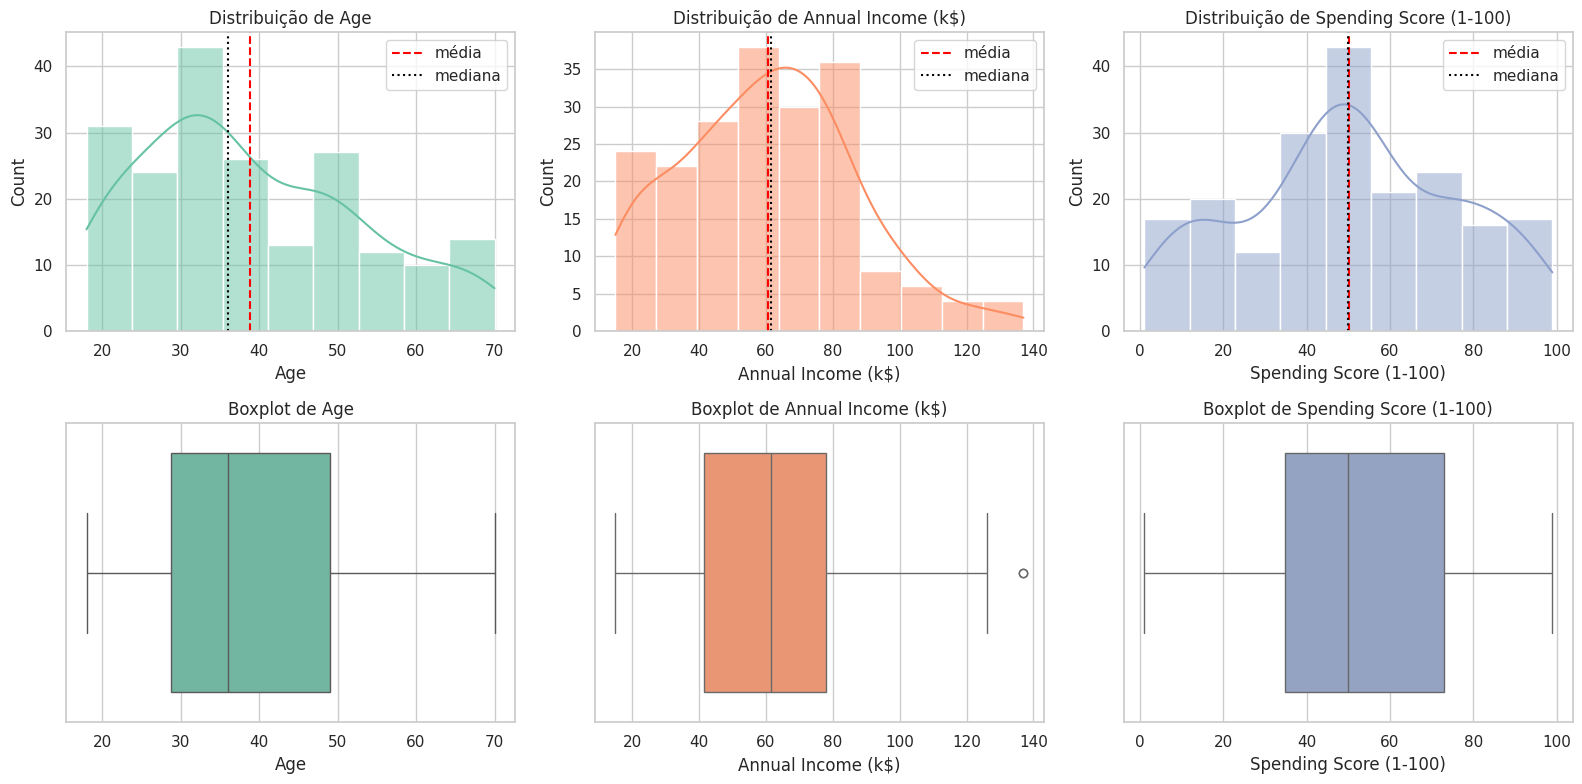

--- Assimetria (skew) e curtose ---


,skew,kurt
Age,0.486,-0.672
Annual Income (k$),0.322,-0.098
Spending Score (1-100),-0.047,-0.827



Outliers por variável (IQR):
Age                       0
Annual Income (k$)        2
Spending Score (1-100)    0


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
198,199,Male,32,137,18
199,200,Male,30,137,83


In [8]:
num_cols = ['Age', COL_INC, COL_SPEND]
cores = sns.color_palette('Set2', 3)

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, c in enumerate(num_cols):
    sns.histplot(df[c], kde=True, ax=axes[0, i], color=cores[i])
    axes[0, i].axvline(df[c].mean(), color='red', ls='--', label='média')
    axes[0, i].axvline(df[c].median(), color='black', ls=':', label='mediana')
    axes[0, i].legend()
    axes[0, i].set_title(f'Distribuição de {c}')
    sns.boxplot(x=df[c], ax=axes[1, i], color=cores[i])
    axes[1, i].set_title(f'Boxplot de {c}')
plt.tight_layout()
plt.show()

print("--- Assimetria (skew) e curtose ---")
display(df[num_cols].agg(['skew', 'kurt']).T.round(3))

def outliers_iqr(s):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

out = pd.DataFrame({c: outliers_iqr(df[c]) for c in num_cols})
print("\nOutliers por variável (IQR):")
print(out.sum().to_string())
display(df[out.any(axis=1)])

**Decisão sobre outliers:** se houver pontos sinalizados (tipicamente as maiores rendas), eles são **clientes legítimos de alta renda** e não erros de digitação. Como representam um grupo de negócio real, **mantemos** esses pontos.

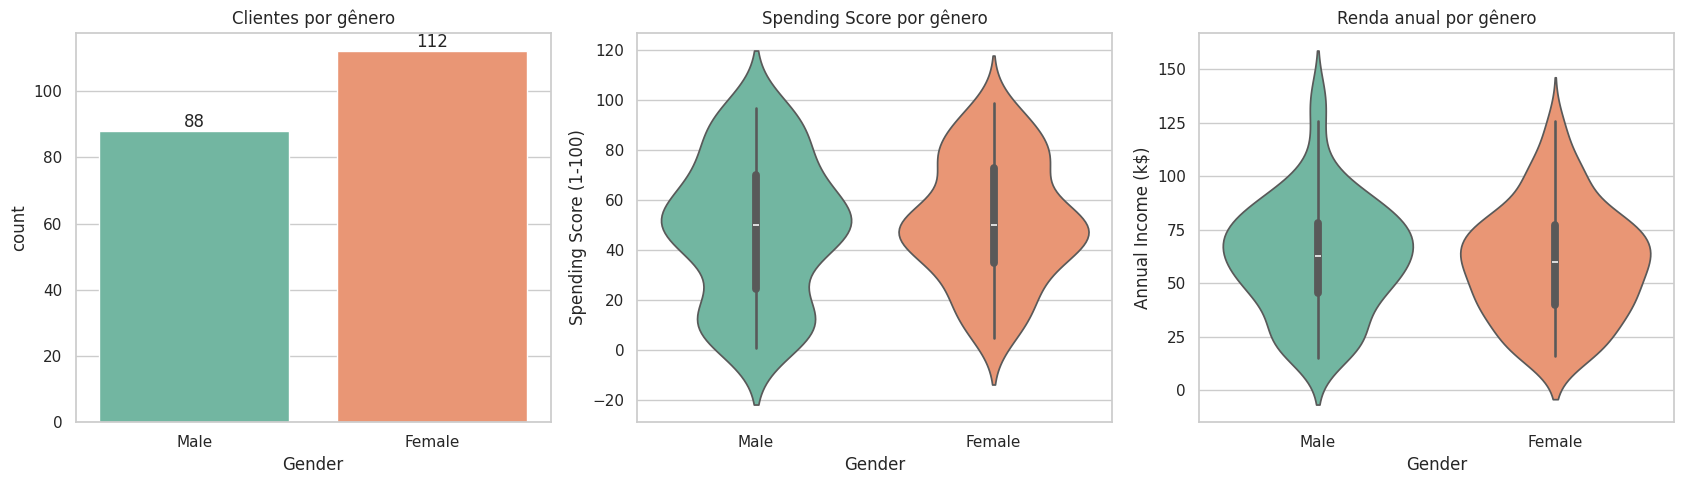

--- Teste de Mann-Whitney (Male vs Female) ---
Age                       p-valor = 0.624  -> sem diferença significativa
Annual Income (k$)        p-valor = 0.414  -> sem diferença significativa
Spending Score (1-100)    p-valor = 0.571  -> sem diferença significativa


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.countplot(data=df, x='Gender', palette='Set2', ax=axes[0])
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                     ha='center', va='bottom')
axes[0].set_title('Clientes por gênero')

sns.violinplot(data=df, x='Gender', y=COL_SPEND, palette='Set2', ax=axes[1])
axes[1].set_title('Spending Score por gênero')

sns.violinplot(data=df, x='Gender', y=COL_INC, palette='Set2', ax=axes[2])
axes[2].set_title('Renda anual por gênero')
plt.tight_layout()
plt.show()

print("--- Teste de Mann-Whitney (Male vs Female) ---")
for c in num_cols:
    h = df.loc[df['Gender'] == 'Male', c]
    m = df.loc[df['Gender'] == 'Female', c]
    stat, p = stats.mannwhitneyu(h, m)
    print(f"{c:25s} p-valor = {p:.3f}  ->", "diferença significativa" if p < 0.05 else "sem diferença significativa")

### 3.5 Correlação entre variáveis

Calculamos duas correlações: **Pearson** (relações lineares) e **Spearman** (relações monotônicas, robusta a outliers). O gênero entra codificado como 0/1.

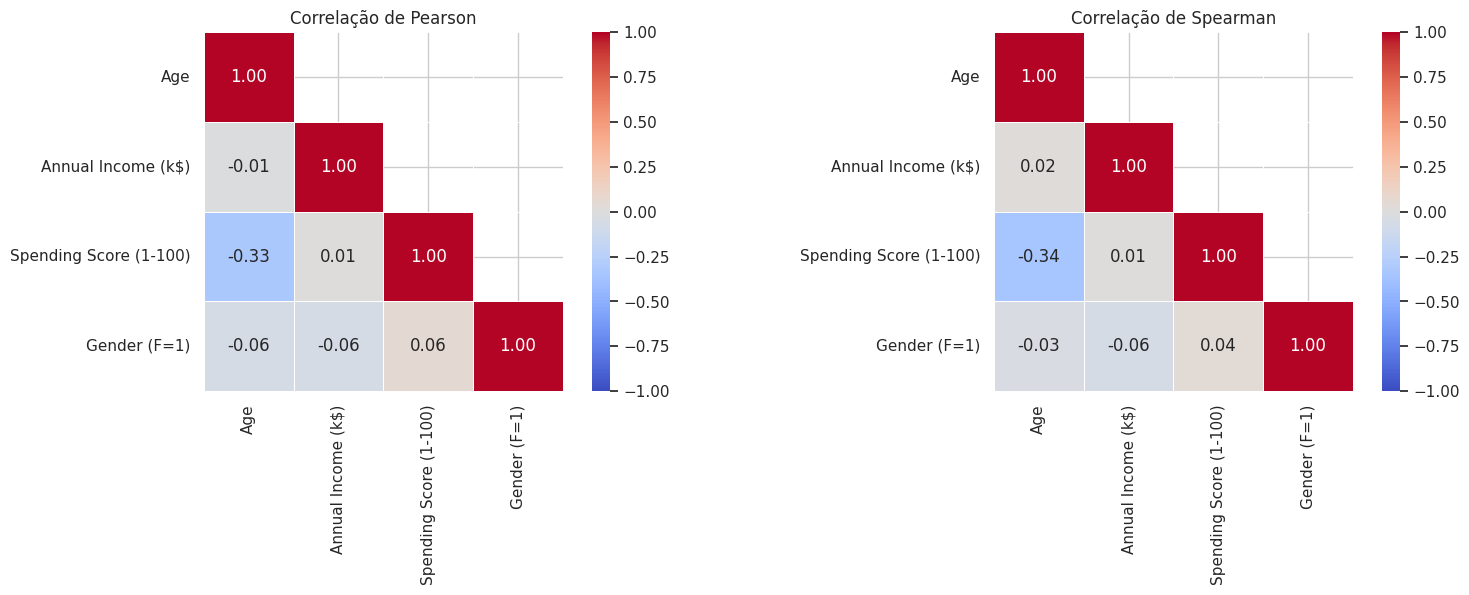

correlação
Spending Score (1-100) Age                         -0.327
Gender (F=1)           Age                         -0.061
                       Spending Score (1-100)       0.058
                       Annual Income (k$)          -0.056
Annual Income (k$)     Age                         -0.012
Spending Score (1-100) Annual Income (k$)           0.010

In [11]:
df_corr = df[num_cols].copy()
df_corr['Gender (F=1)'] = (df['Gender'] == 'Female').astype(int)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, metodo in zip(axes, ['pearson', 'spearman']):
    corr = df_corr.corr(method=metodo)
    mascara_tri = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
                mask=mascara_tri, square=True, linewidths=.5, ax=ax)
    ax.set_title(f'Correlação de {metodo.capitalize()}')
plt.tight_layout()
plt.show()

pares_corr = (df_corr.corr().where(~np.triu(np.ones((4, 4), dtype=bool)))
              .stack().rename('correlação').sort_values(key=abs, ascending=False))
display(pares_corr.to_frame().round(3))

**Insights da correlação**

* **Renda × Gasto ≈ 0**: renda anual não prevê o gasto. Esse é justamente o motivo de a segmentação ser interessante, pois há clientes de renda alta que gastam pouco e vice-versa.
* **Idade × Gasto: correlação negativa moderada**, a única relação linear relevante.
* **Variáveis pouco correlacionadas entre si** significam pouca redundância, então todas carregam informação distinta (bom para clusterização, e o PCA não vai "comprimir" muito).

## 4. Feature Engineering e Padronização

Criamos novas variáveis para enriquecer a análise e a interpretação dos clusters:

| Nova variável | Definição | Motivação |
|---|---|---|
| `Gender_bin` | Female = 1, Male = 0 | Permitir uso do gênero em algoritmos numéricos |
| `Age_group` | Faixas etárias 18-25, 26-35, 36-50, 51+ | Interpretação por geração |
| `Income_group` / `Spending_group` | Tercis (baixa/média/alta) | Segmentação por regras de negócio |
| `Spend_to_Income` | Score de gasto ÷ renda | "Quanto o cliente gasta por unidade de renda" |
| `Income_pct`, `Spend_pct`, `Gap_pct` | Percentil de renda, de gasto e a diferença | Cliente que gasta acima/abaixo do esperado para sua renda |

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Gender_bin,Age_group,Income_group,Spending_group,Spend_to_Income,Income_pct,Spend_pct,Gap_pct
0,1,Male,19,15,39,0,18-25,Baixa,Baixo,2.600000,0.0075,0.2925,0.2850
1,2,Male,21,15,81,0,18-25,Baixa,Alto,5.400000,0.0075,0.8575,0.8500
2,3,Female,20,16,6,1,18-25,Baixa,Baixo,0.375000,0.0175,0.0525,0.0350
3,4,Female,23,16,77,1,18-25,Baixa,Alto,4.812500,0.0175,0.8300,0.8125
4,5,Female,31,17,40,1,26-35,Baixa,Baixo,2.352941,0.0275,0.3075,0.2800


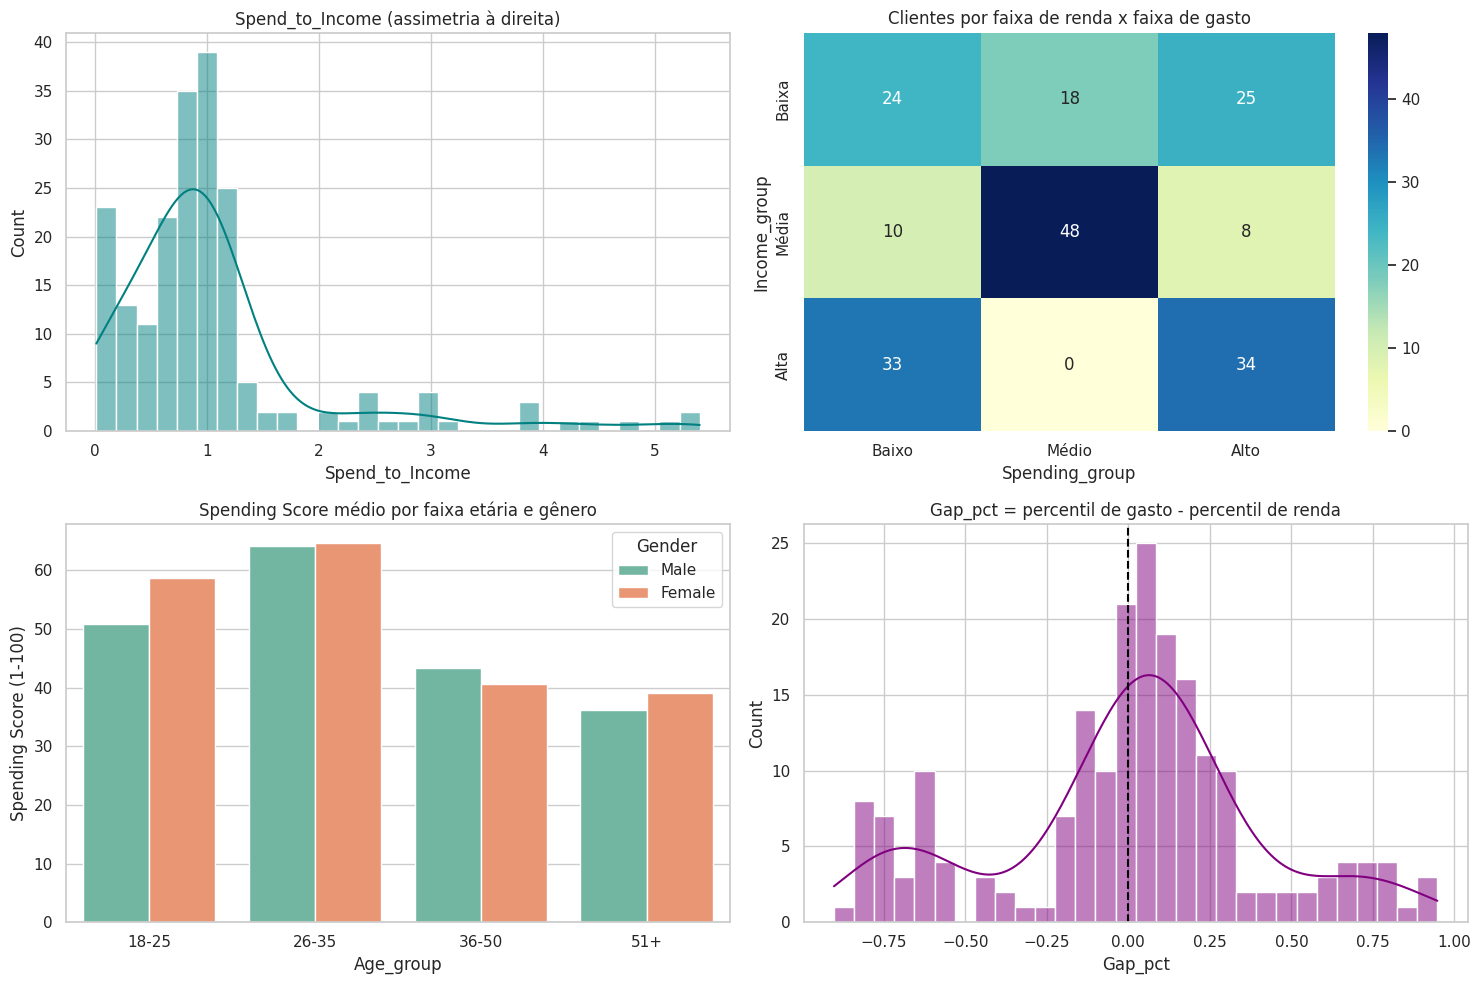

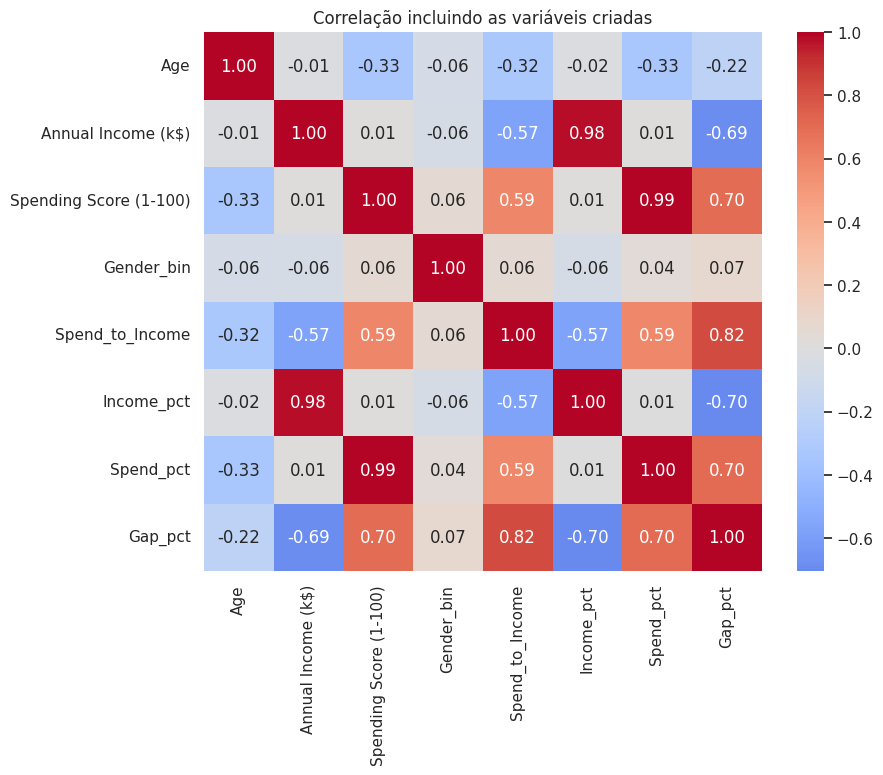

In [12]:
fe = df.copy()
fe['Gender_bin'] = (fe['Gender'] == 'Female').astype(int)
fe['Age_group'] = pd.cut(fe['Age'], bins=[17, 25, 35, 50, 100], labels=['18-25', '26-35', '36-50', '51+'])
fe['Income_group'] = pd.qcut(fe[COL_INC].rank(method='first'), 3, labels=['Baixa', 'Média', 'Alta'])
fe['Spending_group'] = pd.qcut(fe[COL_SPEND].rank(method='first'), 3, labels=['Baixo', 'Médio', 'Alto'])
fe['Spend_to_Income'] = fe[COL_SPEND] / fe[COL_INC]
fe['Income_pct'] = fe[COL_INC].rank(pct=True)
fe['Spend_pct'] = fe[COL_SPEND].rank(pct=True)
fe['Gap_pct'] = fe['Spend_pct'] - fe['Income_pct']   # >0: gasta acima do esperado para a renda

display(fe.head())

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

sns.histplot(fe['Spend_to_Income'], kde=True, bins=30, ax=axes[0, 0], color='teal')
axes[0, 0].set_title('Spend_to_Income (assimetria à direita)')

tabela = pd.crosstab(fe['Income_group'], fe['Spending_group'])
sns.heatmap(tabela, annot=True, fmt='d', cmap='YlGnBu', ax=axes[0, 1])
axes[0, 1].set_title('Clientes por faixa de renda x faixa de gasto')

sns.barplot(data=fe, x='Age_group', y=COL_SPEND, hue='Gender', palette='Set2', ax=axes[1, 0], errorbar=None)
axes[1, 0].set_title('Spending Score médio por faixa etária e gênero')

sns.histplot(fe['Gap_pct'], kde=True, bins=30, ax=axes[1, 1], color='purple')
axes[1, 1].axvline(0, color='black', ls='--')
axes[1, 1].set_title('Gap_pct = percentil de gasto - percentil de renda')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 7))
num_fe = fe.select_dtypes(include='number').drop(columns='CustomerID')
sns.heatmap(num_fe.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlação incluindo as variáveis criadas')
plt.show()

### 4.1 Padronização (StandardScaler)

O K-Means e a maioria dos algoritmos usam **distância euclidiana**; variáveis em escalas diferentes (renda vai até 137, idade até 70, gênero é 0/1) fariam as de maior escala dominarem. Padronizamos com $z = (x-\mu)/\sigma$.

Definimos três conjuntos de variáveis para experimentar:

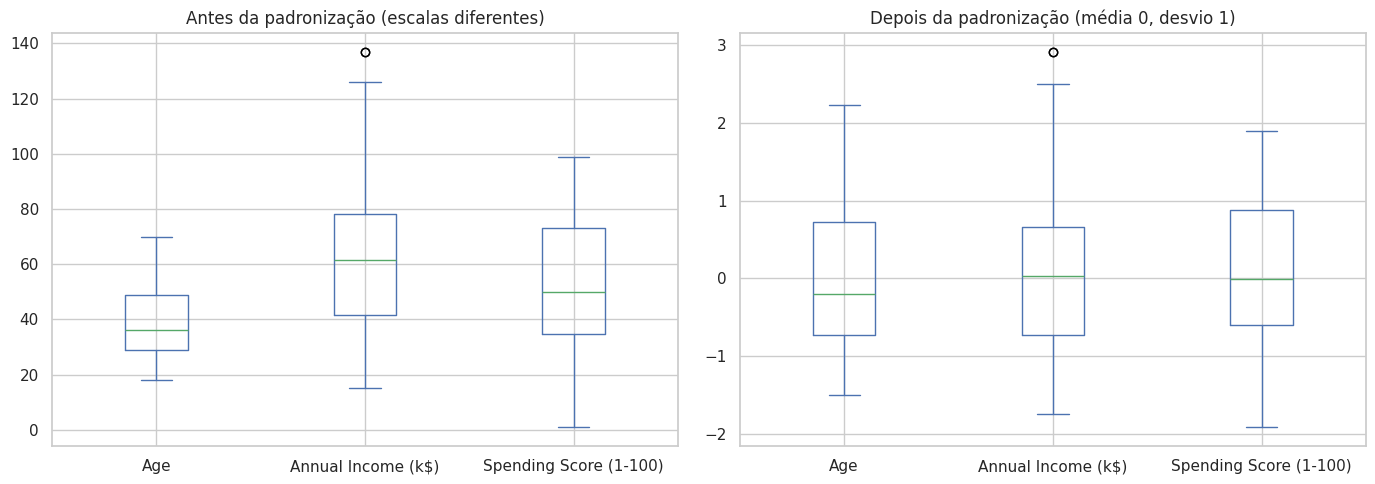

In [13]:
FEATURE_SETS = {
    'Base (Renda + Gasto)'          : [COL_INC, COL_SPEND],
    'Estendido (+Idade)'            : ['Age', COL_INC, COL_SPEND],
    'Estendido (+Idade +Gênero)'    : ['Age', 'Gender_bin', COL_INC, COL_SPEND],
}
X_scaled = {nome: StandardScaler().fit_transform(fe[cols]) for nome, cols in FEATURE_SETS.items()}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fe[['Age', COL_INC, COL_SPEND]].plot(kind='box', ax=axes[0])
axes[0].set_title('Antes da padronização (escalas diferentes)')
pd.DataFrame(X_scaled['Estendido (+Idade)'], columns=['Age', COL_INC, COL_SPEND]).plot(kind='box', ax=axes[1])
axes[1].set_title('Depois da padronização (média 0, desvio 1)')
plt.tight_layout()
plt.show()

## 5. PCA - Análise de Componentes Principais

O PCA projeta os dados em novos eixos (componentes) ortogonais que **maximizam a variância explicada**. Usamos PCA para:

1. Verificar quanta **redundância** existe entre as variáveis;
2. Entender **quais variáveis dominam cada componente** (loadings);
3. Visualizar dados com mais de 2 dimensões em um plano 2D.

Aplicamos o PCA às 4 variáveis padronizadas (`Age`, `Gender_bin`, `Renda`, `Gasto`).

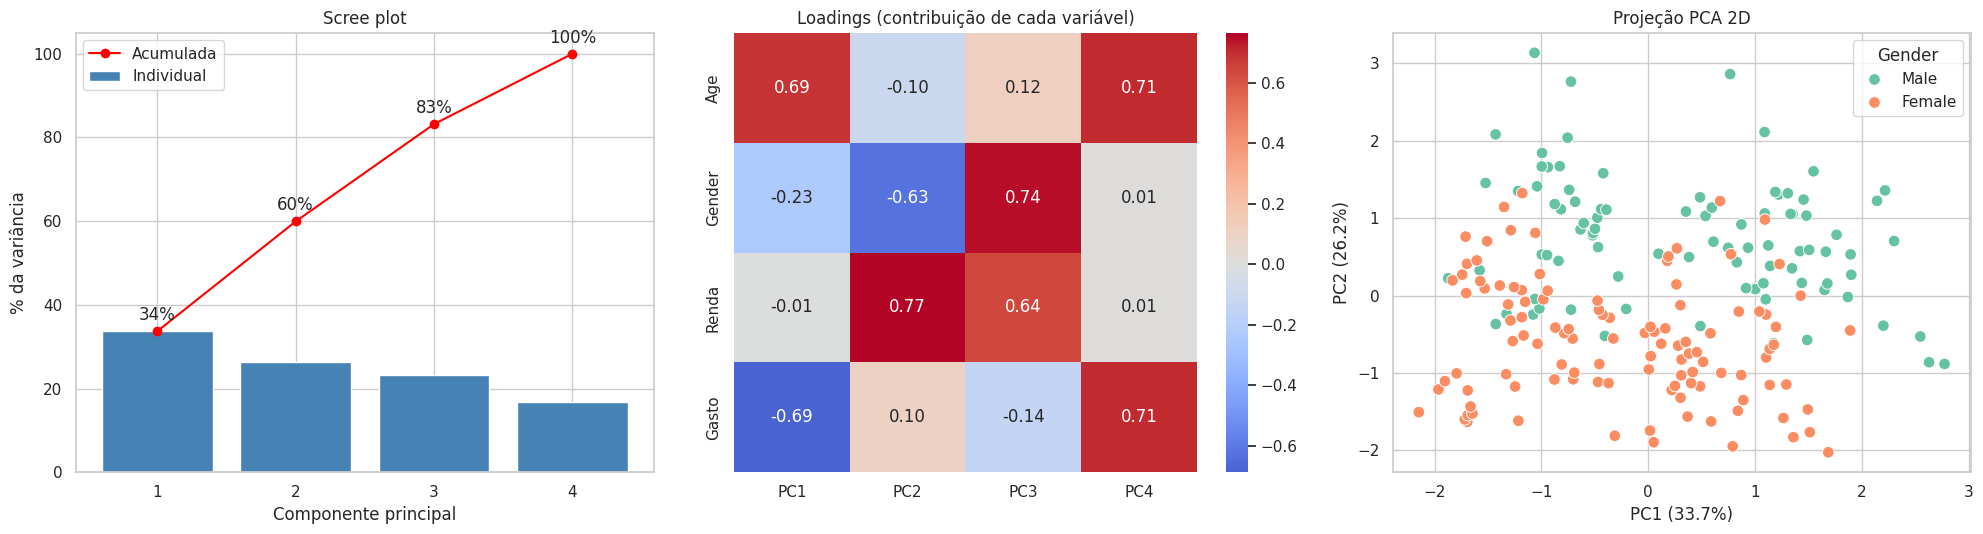

Variância explicada: [33.7 26.2 23.3 16.8] %
PC1+PC2 explicam 59.9% da variância


In [14]:
cols_pca = ['Age', 'Gender_bin', COL_INC, COL_SPEND]
Xp = StandardScaler().fit_transform(fe[cols_pca])
pca = PCA(random_state=SEED).fit(Xp)
var = pca.explained_variance_ratio_
cum = np.cumsum(var)

loadings = pd.DataFrame(pca.components_.T, index=['Age', 'Gender', 'Renda', 'Gasto'],
                        columns=[f'PC{i+1}' for i in range(len(var))])
X_pca = pca.transform(Xp)

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

axes[0].bar(range(1, len(var)+1), var*100, color='steelblue', label='Individual')
axes[0].plot(range(1, len(var)+1), cum*100, 'o-', color='red', label='Acumulada')
for i, v in enumerate(cum):
    axes[0].annotate(f'{v*100:.0f}%', (i+1, v*100), textcoords='offset points', xytext=(0, 8), ha='center')
axes[0].set_xticks(range(1, len(var)+1))
axes[0].set_xlabel('Componente principal'); axes[0].set_ylabel('% da variância')
axes[0].set_title('Scree plot'); axes[0].legend()

sns.heatmap(loadings, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1])
axes[1].set_title('Loadings (contribuição de cada variável)')

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=fe['Gender'], palette='Set2', s=70, ax=axes[2])
axes[2].set_xlabel(f'PC1 ({var[0]*100:.1f}%)'); axes[2].set_ylabel(f'PC2 ({var[1]*100:.1f}%)')
axes[2].set_title('Projeção PCA 2D')
plt.tight_layout()
plt.show()

print("Variância explicada:", np.round(var*100, 1), "%")
print(f"PC1+PC2 explicam {cum[1]*100:.1f}% da variância")

**Interpretação do PCA**

* A variância fica **distribuída entre vários componentes** (nenhum domina), confirmando a baixa correlação vista na seção 3.5: as variáveis não são redundantes, então **reduzir dimensionalidade não é essencial** aqui.
* Os *loadings* mostram quais variáveis formam cada componente (por exemplo, um componente liga Idade e Gasto com sinais opostos, refletindo a correlação negativa).
* Por isso o PCA é usado principalmente como **ferramenta de visualização** dos clusters em 2D (usaremos nas seções 8 e 10).

## 6. Escolhendo o número de clusters (K)

O K-Means exige definir $K$ antecipadamente. Usamos quatro métricas complementares para K de 2 a 10:

| Métrica | Interpretação | Melhor valor |
|---|---|---|
| **WCSS / Inércia** (Elbow) | Soma dos quadrados intra-cluster | "Cotovelo" na curva |
| **Silhouette** | Coesão vs separação (−1 a 1) | Máximo |
| **Calinski-Harabasz** | Razão variância entre / dentro | Máximo |
| **Davies-Bouldin** | Similaridade média entre clusters | Mínimo |

Começamos pelo **Método do Cotovelo (Elbow Method)** usando as colunas `Annual Income` e `Spending Score` (facilita a visualização em 2D).

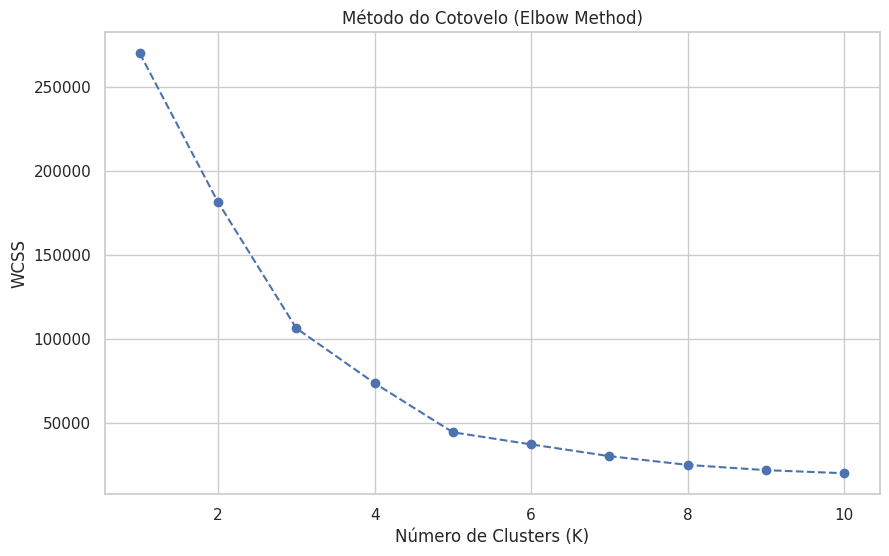

In [15]:
X = df.iloc[:, [3, 4]].values   # Renda anual e Spending Score (modelo base)

wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Método do Cotovelo (Elbow Method)')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('WCSS')
plt.show()

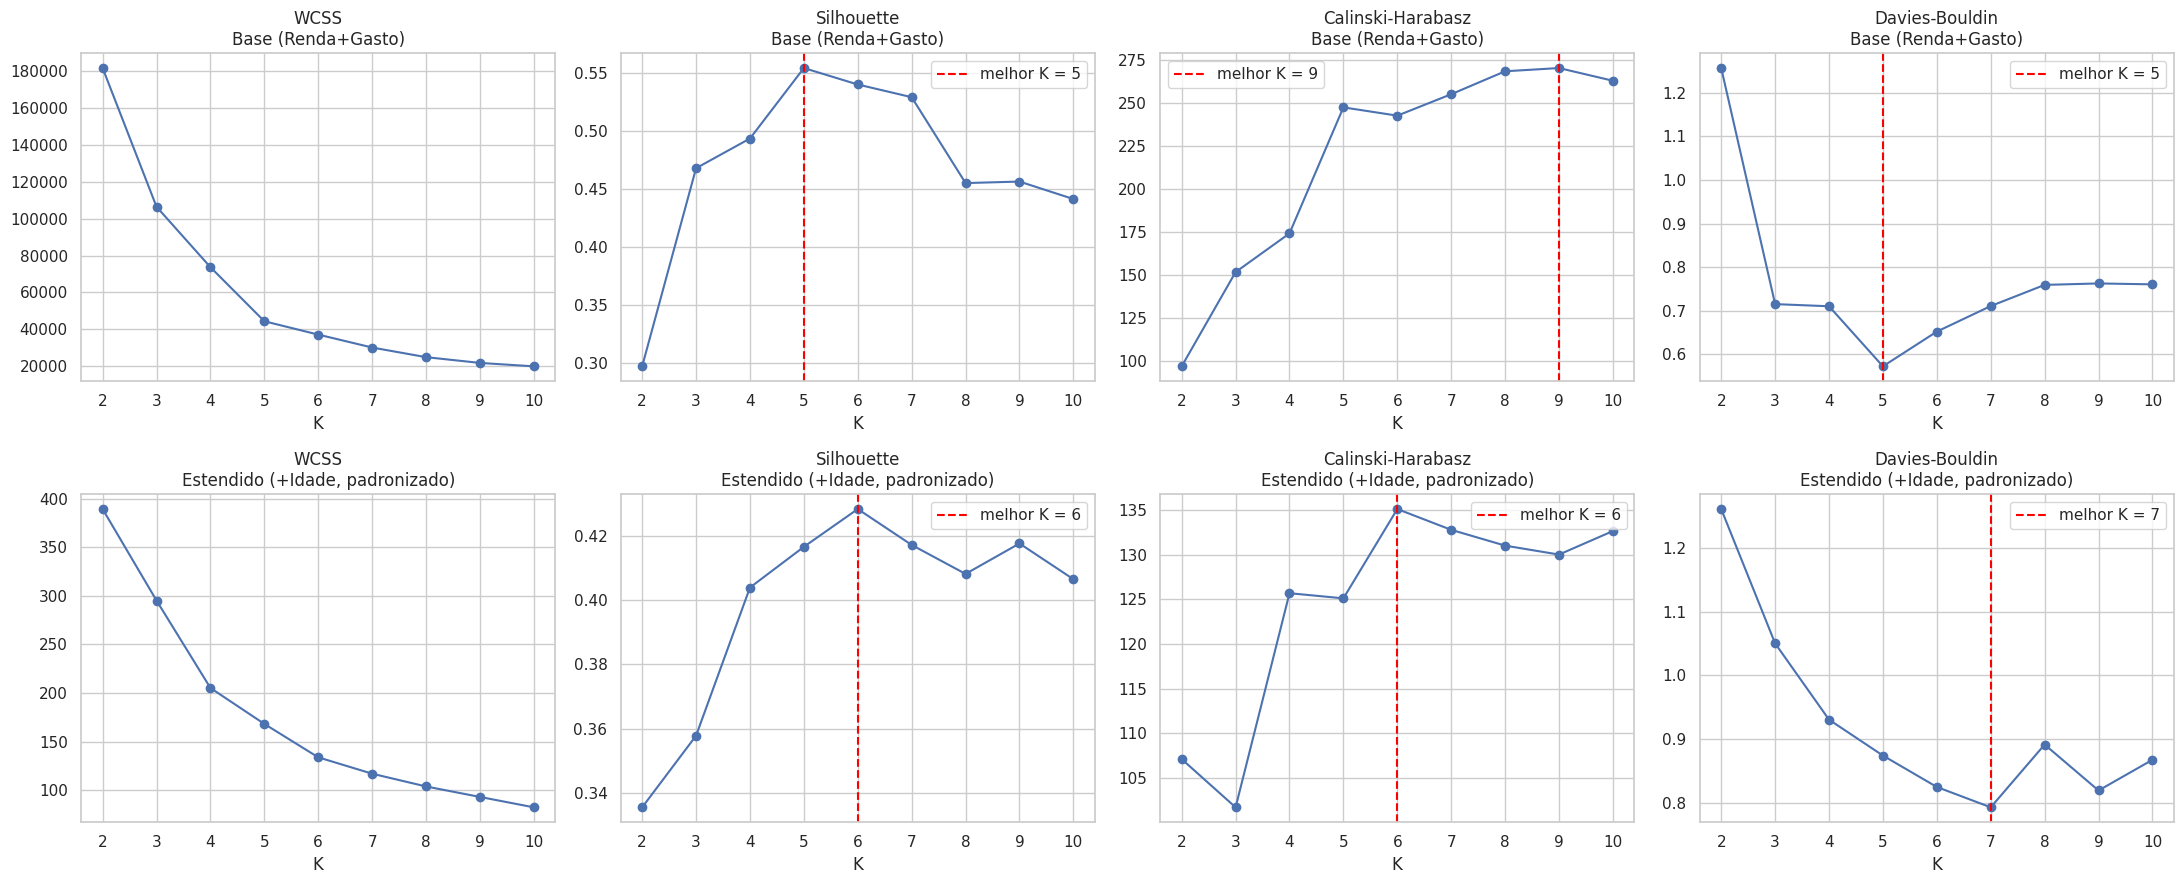

--- Métricas por K (modelo base) ---


,WCSS,Silhouette,Calinski-Harabasz,Davies-Bouldin
k,,,,
2,181363.596,0.297,96.747,1.257
3,106348.373,0.468,151.557,0.715
4,73679.789,0.493,174.064,0.710
5,44448.455,0.554,247.359,0.573
6,37233.815,0.540,242.538,0.652
7,30241.344,0.529,255.003,0.711
8,25036.418,0.455,268.349,0.759
9,21916.795,0.456,270.228,0.763
10,20072.071,0.441,262.846,0.761


In [16]:
def avaliar_k(X, ks=range(2, 11)):
    linhas = []
    for k in ks:
        km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=SEED).fit(X)
        lab = km.labels_
        linhas.append({'k': k, 'WCSS': km.inertia_,
                       'Silhouette': silhouette_score(X, lab),
                       'Calinski-Harabasz': calinski_harabasz_score(X, lab),
                       'Davies-Bouldin': davies_bouldin_score(X, lab)})
    return pd.DataFrame(linhas).set_index('k')

res_base = avaliar_k(X)
res_ext = avaliar_k(X_scaled['Estendido (+Idade)'])

fig, axes = plt.subplots(2, 4, figsize=(22, 9))
for linha, (titulo, res) in enumerate([('Base (Renda+Gasto)', res_base), ('Estendido (+Idade, padronizado)', res_ext)]):
    for col, metrica in enumerate(res.columns):
        ax = axes[linha, col]
        ax.plot(res.index, res[metrica], 'o-')
        melhor = res[metrica].idxmin() if metrica == 'Davies-Bouldin' else (res[metrica].idxmax() if metrica != 'WCSS' else None)
        if melhor is not None:
            ax.axvline(melhor, color='red', ls='--', label=f'melhor K = {melhor}')
            ax.legend()
        ax.set_title(f'{metrica}\n{titulo}')
        ax.set_xlabel('K')
plt.tight_layout()
plt.show()

print("--- Métricas por K (modelo base) ---")
display(res_base.round(3))

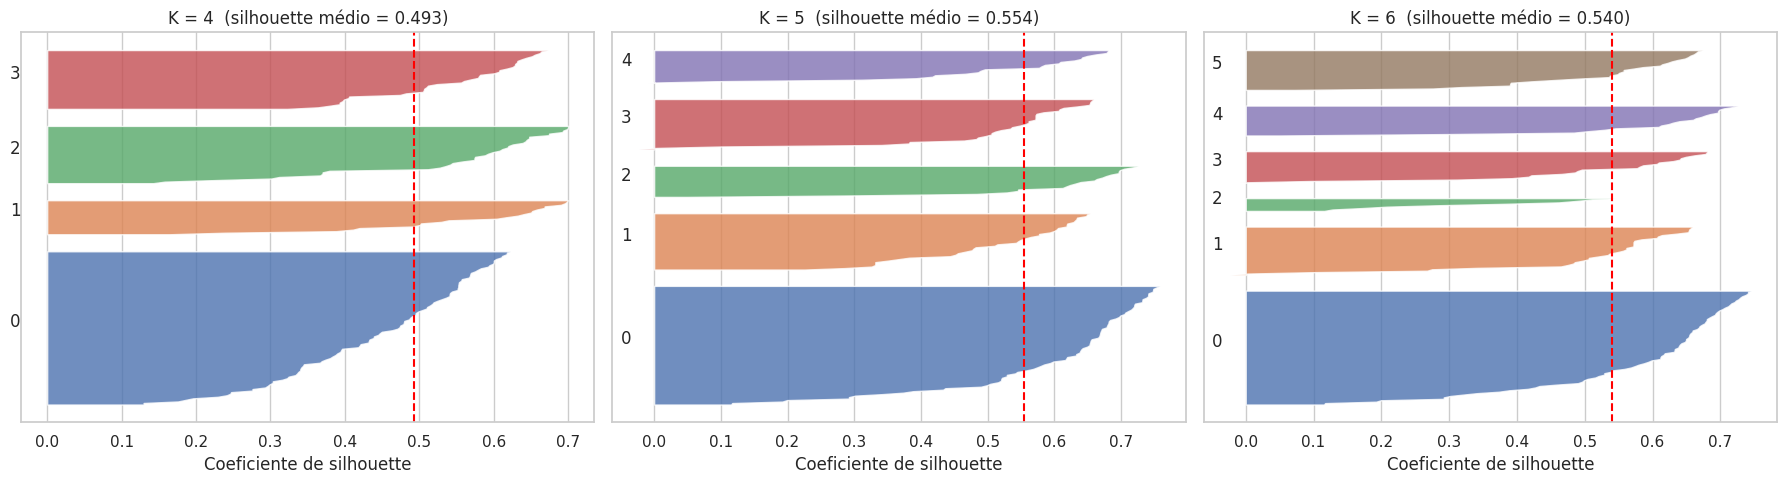

In [17]:
# Gráfico de silhouette por amostra para K = 4, 5 e 6 (modelo base)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, k in zip(axes, [4, 5, 6]):
    lab = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X)
    sil = silhouette_samples(X, lab)
    y_inf = 10
    for c in range(k):
        s_c = np.sort(sil[lab == c])
        ax.fill_betweenx(np.arange(y_inf, y_inf + len(s_c)), 0, s_c, alpha=0.8)
        ax.text(-0.05, y_inf + 0.5 * len(s_c), str(c))
        y_inf += len(s_c) + 10
    ax.axvline(sil.mean(), color='red', ls='--')
    ax.set_title(f'K = {k}  (silhouette médio = {sil.mean():.3f})')
    ax.set_xlabel('Coeficiente de silhouette'); ax.set_yticks([])
plt.tight_layout()
plt.show()

**Conclusão da escolha de K:** o cotovelo e o silhouette indicam $K=5$ para o modelo base (Renda × Gasto). O gráfico de silhouette por amostra confirma que, com $K=5$, os clusters têm largura parecida e poucos pontos com valor negativo.

## 7. Modelo base: K-Means ($K=5$)

Treinamos o K-Means dividindo os clientes em 5 grupos e visualizamos os clusters com seus centroides.

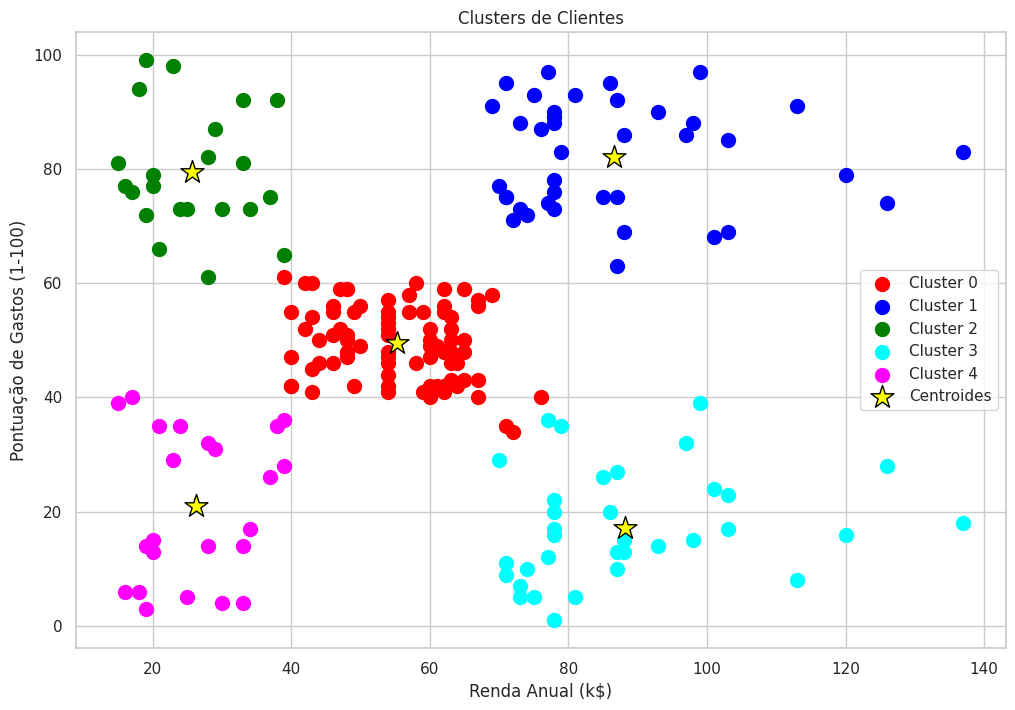

Silhouette         : 0.554
Calinski-Harabasz  : 247.4
Davies-Bouldin     : 0.573
Inércia (WCSS)     : 44448.5

Centroides (Renda, Gasto):


,Renda (k$),Gasto (1-100)
0,55.3,49.5
1,86.5,82.1
2,25.7,79.4
3,88.2,17.1
4,26.3,20.9


In [18]:
kmeans = KMeans(n_clusters=5, init='k-means++', random_state=42, n_init=10)
y_kmeans = kmeans.fit_predict(X)

df['Cluster'] = y_kmeans

# Visualizando os Clusters
plt.figure(figsize=(12,8))

cores = ['red', 'blue', 'green', 'cyan', 'magenta']
for i in range(5):
    plt.scatter(X[y_kmeans == i, 0], X[y_kmeans == i, 1], s=100, c=cores[i], label=f'Cluster {i}')

plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=300, c='yellow', label='Centroides', edgecolor='black', marker='*')

plt.title('Clusters de Clientes')
plt.xlabel('Renda Anual (k$)')
plt.ylabel('Pontuação de Gastos (1-100)')
plt.legend()
plt.show()

print(f"Silhouette         : {silhouette_score(X, y_kmeans):.3f}")
print(f"Calinski-Harabasz  : {calinski_harabasz_score(X, y_kmeans):.1f}")
print(f"Davies-Bouldin     : {davies_bouldin_score(X, y_kmeans):.3f}")
print(f"Inércia (WCSS)     : {kmeans.inertia_:.1f}")
print("\nCentroides (Renda, Gasto):")
display(pd.DataFrame(kmeans.cluster_centers_, columns=['Renda (k$)', 'Gasto (1-100)']).round(1))

## 8. Interpretação dos grupos do K-Means

Clusters são apenas números (0 a 4); o valor para o negócio vem de **entender e nomear cada grupo**. Calculamos o perfil médio de cada cluster e atribuímos um nome com base em regras simples de renda e gasto.

In [19]:
def nome_perfil(renda, gasto):
    r = 'baixa' if renda < 40 else ('alta' if renda >= 70 else 'média')
    g = 'baixo' if gasto < 35 else ('alto' if gasto > 65 else 'médio')
    nomes = {('baixa', 'baixo'): 'Conservadores',
             ('baixa', 'alto') : 'Impulsivos',
             ('alta',  'baixo'): 'Cuidadosos',
             ('alta',  'alto') : 'Alvo premium',
             ('média', 'médio'): 'Perfil médio (massa)'}
    return nomes.get((r, g), f'Renda {r} / Gasto {g}')

perfil = df.groupby('Cluster').agg(
    Clientes=('CustomerID', 'count'),
    Idade_media=('Age', 'mean'),
    Renda_media=(COL_INC, 'mean'),
    Gasto_medio=(COL_SPEND, 'mean'),
    Pct_Mulheres=('Gender', lambda s: (s == 'Female').mean() * 100)).round(1)
perfil['% da base'] = (perfil['Clientes'] / len(df) * 100).round(1)
perfil['Perfil'] = [nome_perfil(r, g) for r, g in zip(perfil['Renda_media'], perfil['Gasto_medio'])]
dup = perfil['Perfil'].duplicated(keep=False)
perfil.loc[dup, 'Perfil'] = perfil.loc[dup, 'Perfil'] + ' #' + perfil.loc[dup].index.astype(str)

df['Perfil'] = df['Cluster'].map(perfil['Perfil'])
fe['Cluster'] = df['Cluster']
fe['Perfil'] = df['Perfil']

display(perfil.sort_values('Renda_media'))

,Clientes,Idade_media,Renda_media,Gasto_medio,Pct_Mulheres,% da base,Perfil
Cluster,,,,,,,
2,22,25.3,25.7,79.4,59.1,11.0,Impulsivos
4,23,45.2,26.3,20.9,60.9,11.5,Conservadores
0,81,42.7,55.3,49.5,59.3,40.5,Perfil médio (massa)
1,39,32.7,86.5,82.1,53.8,19.5,Alvo premium
3,35,41.1,88.2,17.1,45.7,17.5,Cuidadosos


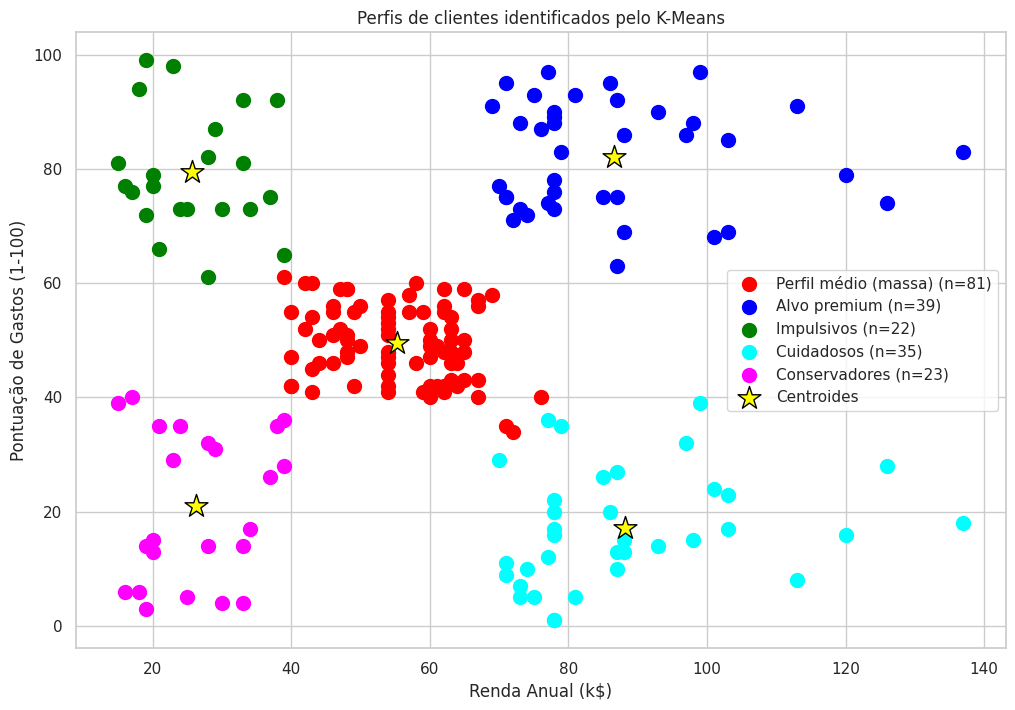

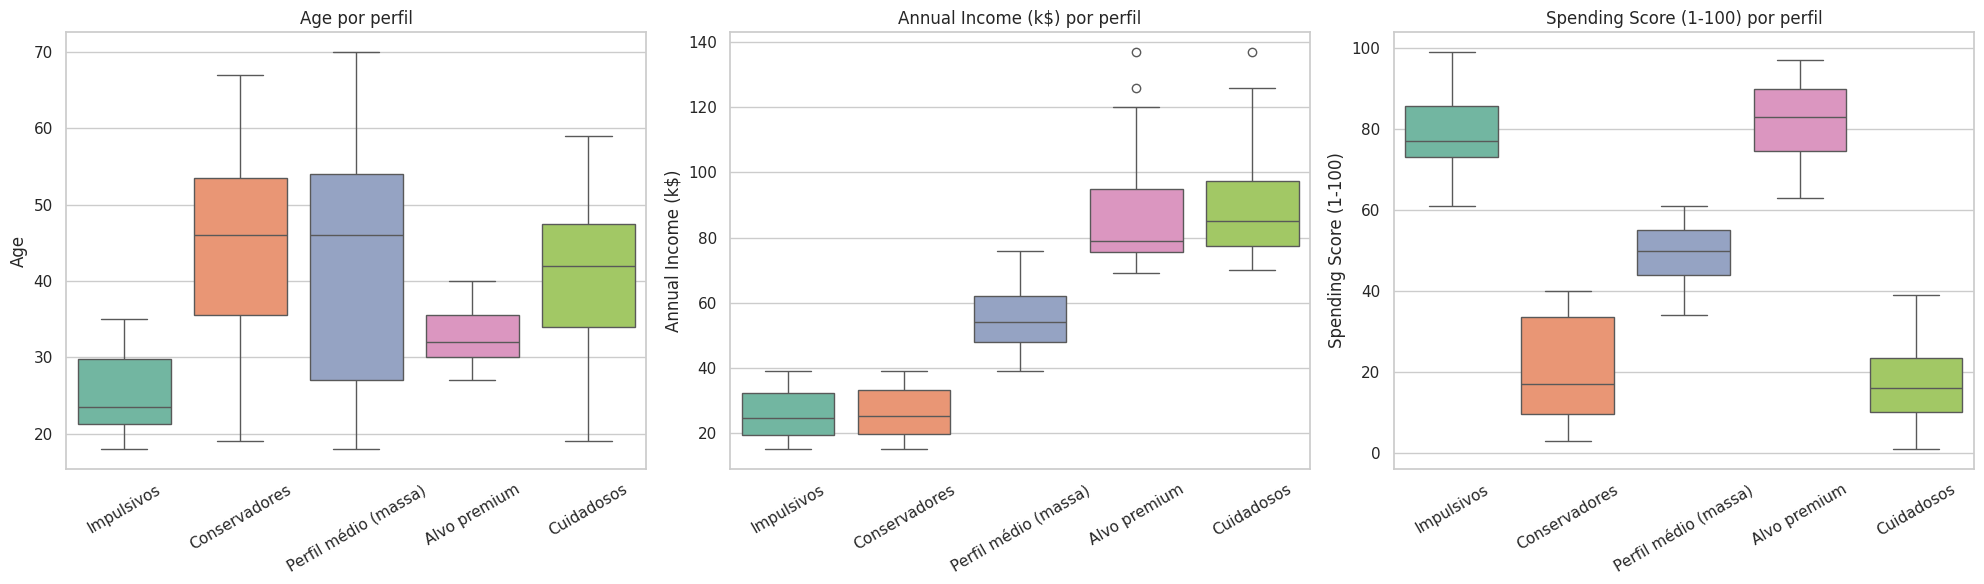

In [20]:
# Dispersão com os perfis nomeados
plt.figure(figsize=(12, 8))
for i in perfil.index:
    plt.scatter(X[y_kmeans == i, 0], X[y_kmeans == i, 1], s=100, c=cores[i],
                label=f"{perfil.loc[i, 'Perfil']} (n={perfil.loc[i, 'Clientes']})")
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=300, c='yellow',
            edgecolor='black', marker='*', label='Centroides')
plt.title('Perfis de clientes identificados pelo K-Means')
plt.xlabel('Renda Anual (k$)'); plt.ylabel('Pontuação de Gastos (1-100)')
plt.legend(); plt.show()

# Distribuição das variáveis por perfil
ordem = perfil.sort_values('Renda_media')['Perfil'].tolist()
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, c in zip(axes, ['Age', COL_INC, COL_SPEND]):
    sns.boxplot(data=df, x='Perfil', y=c, order=ordem, palette='Set2', ax=ax)
    ax.set_title(f'{c} por perfil'); ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

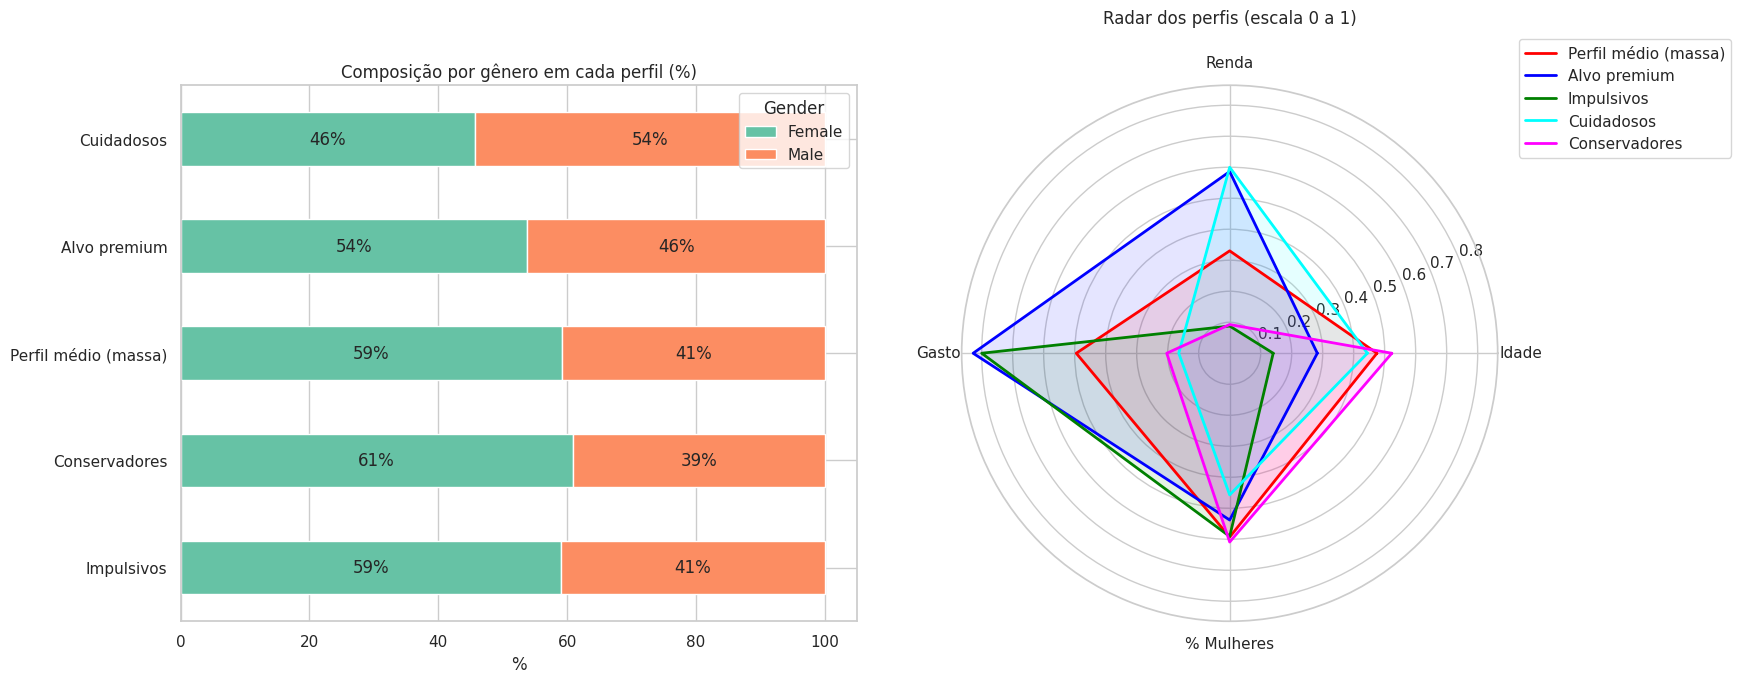

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={'width_ratios': [1, 1.1]})

# Composição por gênero
comp = pd.crosstab(df['Perfil'], df['Gender'], normalize='index').loc[ordem] * 100
comp.plot(kind='barh', stacked=True, color=sns.color_palette('Set2', 2), ax=axes[0])
axes[0].set_title('Composição por gênero em cada perfil (%)')
axes[0].set_xlabel('%'); axes[0].set_ylabel('')
for cont in axes[0].containers:
    axes[0].bar_label(cont, fmt='%.0f%%', label_type='center')

# Radar chart (variáveis normalizadas de 0 a 1)
axes[1].remove()
ax = fig.add_subplot(1, 2, 2, polar=True)
rotulos = ['Idade', 'Renda', 'Gasto', '% Mulheres']
radar = pd.DataFrame({
    'Idade' : (perfil['Idade_media'] - df['Age'].min()) / (df['Age'].max() - df['Age'].min()),
    'Renda' : (perfil['Renda_media'] - df[COL_INC].min()) / (df[COL_INC].max() - df[COL_INC].min()),
    'Gasto' : (perfil['Gasto_medio'] - df[COL_SPEND].min()) / (df[COL_SPEND].max() - df[COL_SPEND].min()),
    '% Mulheres': perfil['Pct_Mulheres'] / 100})
angulos = np.linspace(0, 2 * pi, len(rotulos), endpoint=False).tolist()
angulos += angulos[:1]
for idx, linha in radar.iterrows():
    v = linha.tolist() + linha.tolist()[:1]
    ax.plot(angulos, v, label=perfil.loc[idx, 'Perfil'], color=cores[idx], lw=2)
    ax.fill(angulos, v, alpha=0.1, color=cores[idx])
ax.set_xticks(angulos[:-1]); ax.set_xticklabels(rotulos)
ax.set_title('Radar dos perfis (escala 0 a 1)', y=1.1)
ax.legend(loc='upper right', bbox_to_anchor=(1.45, 1.1))
plt.tight_layout()
plt.show()

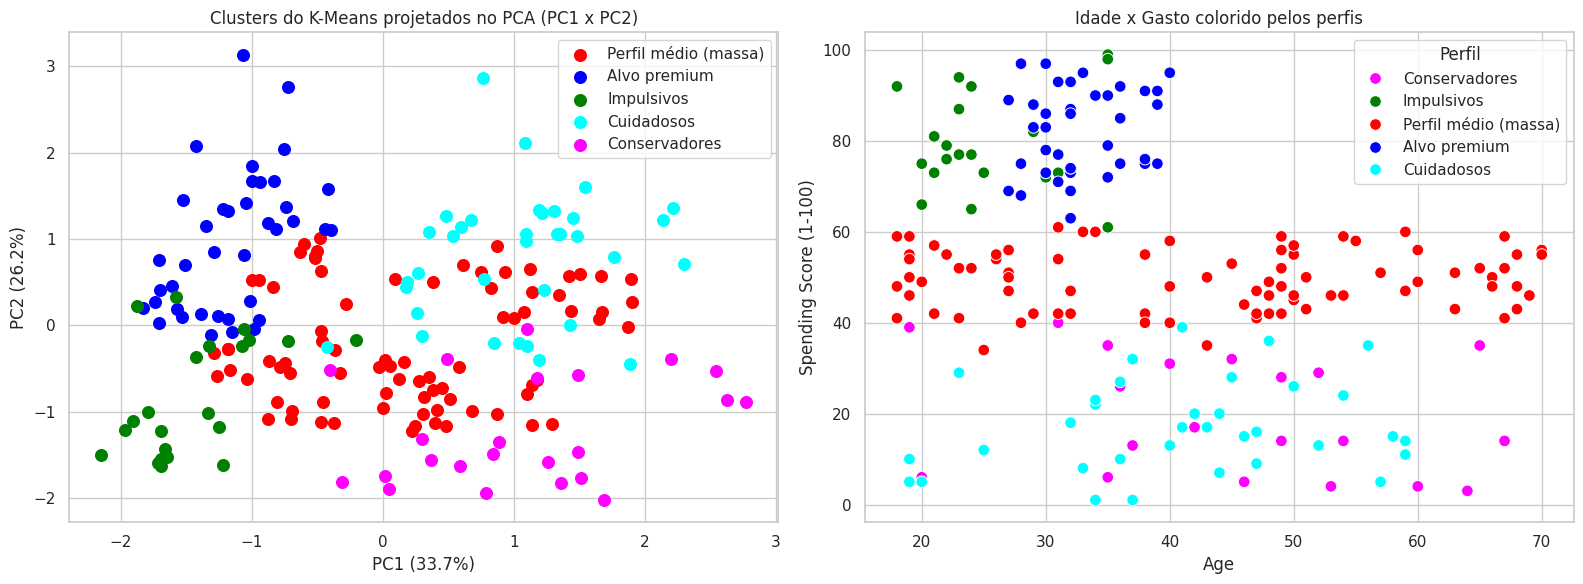

In [22]:
# Clusters do K-Means visualizados no espaço do PCA (4 variáveis)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for i in perfil.index:
    m = (df['Cluster'] == i).values
    axes[0].scatter(X_pca[m, 0], X_pca[m, 1], s=70, c=cores[i], label=perfil.loc[i, 'Perfil'])
axes[0].set_title('Clusters do K-Means projetados no PCA (PC1 x PC2)')
axes[0].set_xlabel(f'PC1 ({var[0]*100:.1f}%)'); axes[0].set_ylabel(f'PC2 ({var[1]*100:.1f}%)')
axes[0].legend()

sns.scatterplot(data=df, x='Age', y=COL_SPEND, hue='Perfil', palette=dict(zip(perfil['Perfil'], [cores[i] for i in perfil.index])),
                s=70, ax=axes[1])
axes[1].set_title('Idade x Gasto colorido pelos perfis')
plt.tight_layout()
plt.show()

### Resumo dos perfis encontrados

| Perfil | Característica | Ação sugerida |
|---|---|---|
| **Alvo premium** (renda alta / gasto alto) | Clientes mais valiosos | Programas de fidelidade, lançamentos, produtos premium |
| **Cuidadosos** (renda alta / gasto baixo) | Têm potencial de gasto não aproveitado | Promoções de custo-benefício, experiências, comunicação de valor |
| **Impulsivos** (renda baixa / gasto alto) | Gastam acima do que a renda sugere (em geral mais jovens) | Parcelamento, campanhas de tendência; atenção ao risco de inadimplência |
| **Conservadores** (renda baixa / gasto baixo) | Sensíveis a preço | Descontos, cupons, liquidações |
| **Perfil médio (massa)** | Maior parte da base, comportamento intermediário | Campanhas gerais e comunicação de massa |

> Os nomes são atribuídos automaticamente por regra sobre os centroides; os números exatos de clientes e médias aparecem na tabela acima.

## 9. Comparação com outros modelos não supervisionados

Para saber se o K-Means é realmente uma boa escolha, comparamos com outras famílias de algoritmos no **mesmo conjunto de dados** (Renda × Gasto, **padronizados**, pois vários algoritmos de densidade e espectrais dependem da escala).

Como não há rótulos verdadeiros, usamos **métricas internas** (Silhouette, Calinski-Harabasz, Davies-Bouldin) e o **ARI (Adjusted Rand Index)** para medir o quanto cada modelo concorda com o K-Means (1 = partições idênticas, 0 = concordância ao acaso).

### 9.1 Ajuste de hiperparâmetros dos modelos que não recebem K

**DBSCAN** precisa de `eps`. Usamos o gráfico das distâncias ao $k$-ésimo vizinho: o ponto onde a curva "sobe" indica o raio em que os pontos deixam de ser densos.

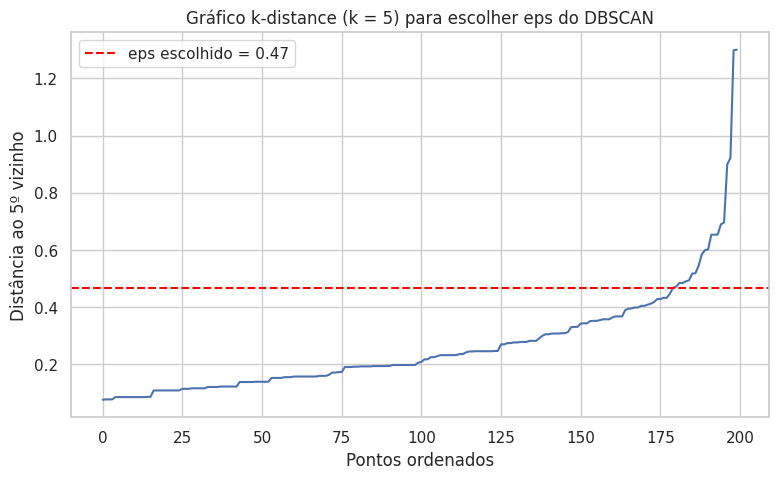

In [23]:
X_s = StandardScaler().fit_transform(X)

# --- DBSCAN: gráfico k-distance ---
k_vizinhos = 5
dist, _ = NearestNeighbors(n_neighbors=k_vizinhos).fit(X_s).kneighbors(X_s)
kdist = np.sort(dist[:, -1])
eps_dbscan = float(np.percentile(kdist, 90))   # ajuste fino possível: troque o percentil se quiser mais/menos ruído

plt.figure(figsize=(9, 5))
plt.plot(kdist)
plt.axhline(eps_dbscan, color='red', ls='--', label=f'eps escolhido = {eps_dbscan:.2f}')
plt.title(f'Gráfico k-distance (k = {k_vizinhos}) para escolher eps do DBSCAN')
plt.xlabel('Pontos ordenados'); plt.ylabel(f'Distância ao {k_vizinhos}º vizinho')
plt.legend(); plt.show()

**Affinity Propagation** não pede $K$, mas depende do parâmetro `preference` (quanto menor, menos clusters). Fazemos uma varredura e escolhemos o valor com melhor silhouette entre os que geram de 2 a 10 clusters.

**Mean Shift** depende da largura de banda (`bandwidth`), estimada automaticamente a partir dos dados.

,preference,clusters,silhouette
0,-0.05,77,0.341
1,-0.10,47,0.415
2,-0.25,36,0.421
3,-0.50,25,0.419
4,-1.00,18,0.424
5,-2.00,13,0.416
6,-4.00,9,0.452
7,-8.00,7,0.453
8,-16.00,5,0.553


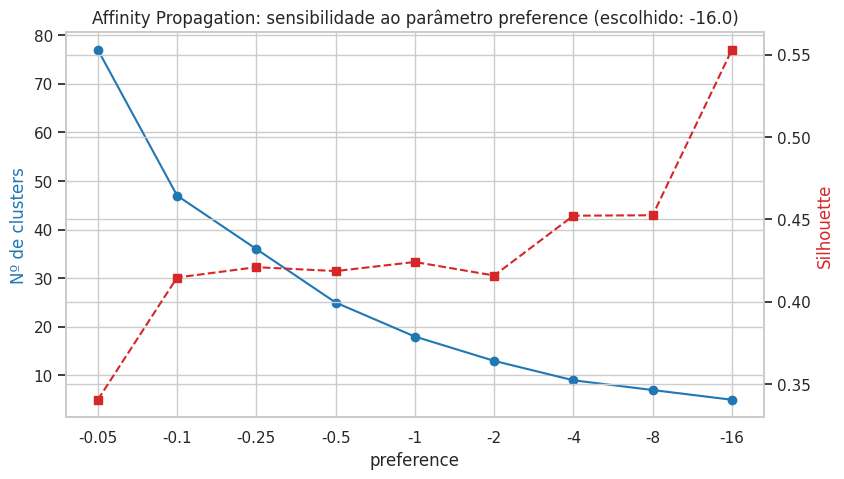

Mean Shift bandwidth estimada: 1.047


In [24]:
# --- Affinity Propagation: varredura de preference ---
prefs = [-0.05, -0.1, -0.25, -0.5, -1, -2, -4, -8, -16]
linhas = []
for p in prefs:
    ap = AffinityPropagation(damping=0.9, preference=p, random_state=SEED, max_iter=500).fit(X_s)
    n = len(ap.cluster_centers_indices_) if ap.cluster_centers_indices_ is not None else 0
    sil = silhouette_score(X_s, ap.labels_) if 2 <= n < len(X_s) else np.nan
    linhas.append({'preference': p, 'clusters': n, 'silhouette': sil})
ap_sweep = pd.DataFrame(linhas)
display(ap_sweep.round(3))

validos = ap_sweep[(ap_sweep['clusters'] >= 2) & (ap_sweep['clusters'] <= 10)].dropna()
pref_ap = float(validos.loc[validos['silhouette'].idxmax(), 'preference']) if len(validos) else -1.0

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(range(len(prefs)), ap_sweep['clusters'], 'o-', color='tab:blue')
ax1.set_ylabel('Nº de clusters', color='tab:blue')
ax2 = ax1.twinx()
ax2.plot(range(len(prefs)), ap_sweep['silhouette'], 's--', color='tab:red')
ax2.set_ylabel('Silhouette', color='tab:red')
ax1.set_xticks(range(len(prefs))); ax1.set_xticklabels(prefs)
ax1.set_xlabel('preference')
plt.title(f'Affinity Propagation: sensibilidade ao parâmetro preference (escolhido: {pref_ap})')
plt.show()

bw = estimate_bandwidth(X_s, quantile=0.2, random_state=SEED)
print(f"Mean Shift bandwidth estimada: {bw:.3f}")

### 9.2 Executando todos os modelos

In [25]:
modelos = {
    'K-Means (k=5)'        : KMeans(n_clusters=5, init='k-means++', n_init=10, random_state=SEED),
    'Aglomerativo (Ward)'  : AgglomerativeClustering(n_clusters=5, linkage='ward'),
    'Aglomerativo (Single)': AgglomerativeClustering(n_clusters=5, linkage='single'),
    'GMM (k=5)'            : GaussianMixture(n_components=5, covariance_type='full', n_init=5, random_state=SEED),
    'BIRCH (k=5)'          : Birch(n_clusters=5),
    'Espectral (k=5)'      : SpectralClustering(n_clusters=5, affinity='nearest_neighbors', n_neighbors=10,
                                                random_state=SEED, assign_labels='kmeans'),
    'DBSCAN'               : DBSCAN(eps=eps_dbscan, min_samples=5),
    'OPTICS'               : OPTICS(min_samples=5, xi=0.05, min_cluster_size=0.05),
    'Affinity Propagation' : AffinityPropagation(damping=0.9, preference=pref_ap, random_state=SEED, max_iter=500),
    'Mean Shift'           : MeanShift(bandwidth=bw, bin_seeding=True),
}

def metricas(Xm, lab):
    ok = lab != -1                       # -1 = ruído (DBSCAN/OPTICS)
    n_cl = len(set(lab[ok]))
    base = {'Clusters': n_cl, 'Ruído': int((~ok).sum())}
    if n_cl >= 2 and ok.sum() > n_cl:
        base.update({'Silhouette': silhouette_score(Xm[ok], lab[ok]),
                     'Calinski-Harabasz': calinski_harabasz_score(Xm[ok], lab[ok]),
                     'Davies-Bouldin': davies_bouldin_score(Xm[ok], lab[ok])})
    else:
        base.update({'Silhouette': np.nan, 'Calinski-Harabasz': np.nan, 'Davies-Bouldin': np.nan})
    return base

labels_modelos = {}
for nome, modelo in modelos.items():
    try:
        labels_modelos[nome] = np.asarray(modelo.fit_predict(X_s))
    except Exception as e:
        print(f"[!] {nome} falhou: {e}")

lab_ref = labels_modelos['K-Means (k=5)']
tabela = pd.DataFrame({nome: {**metricas(X_s, lab),
                              'ARI vs K-Means': adjusted_rand_score(lab_ref, lab)}
                       for nome, lab in labels_modelos.items()}).T
tabela['Clusters'] = tabela['Clusters'].astype(int)
tabela['Ruído'] = tabela['Ruído'].astype(int)
display(tabela.sort_values('Silhouette', ascending=False).round(3))

,Clusters,Ruído,Silhouette,Calinski-Harabasz,Davies-Bouldin,ARI vs K-Means
OPTICS,8,96,0.609,486.869,0.543,0.176
K-Means (k=5),5,0,0.555,248.649,0.572,1.000
Aglomerativo (Ward),5,0,0.554,244.410,0.578,0.942
GMM (k=5),5,0,0.554,244.940,0.576,0.956
Affinity Propagation,5,0,0.553,246.800,0.567,0.929
Espectral (k=5),5,0,0.545,243.797,0.586,0.958
Mean Shift,3,0,0.464,150.181,0.723,0.542
BIRCH (k=5),5,0,0.414,125.949,0.698,0.651
DBSCAN,2,11,0.396,87.887,0.768,0.273
Aglomerativo (Single),5,0,0.276,5.647,0.423,0.010


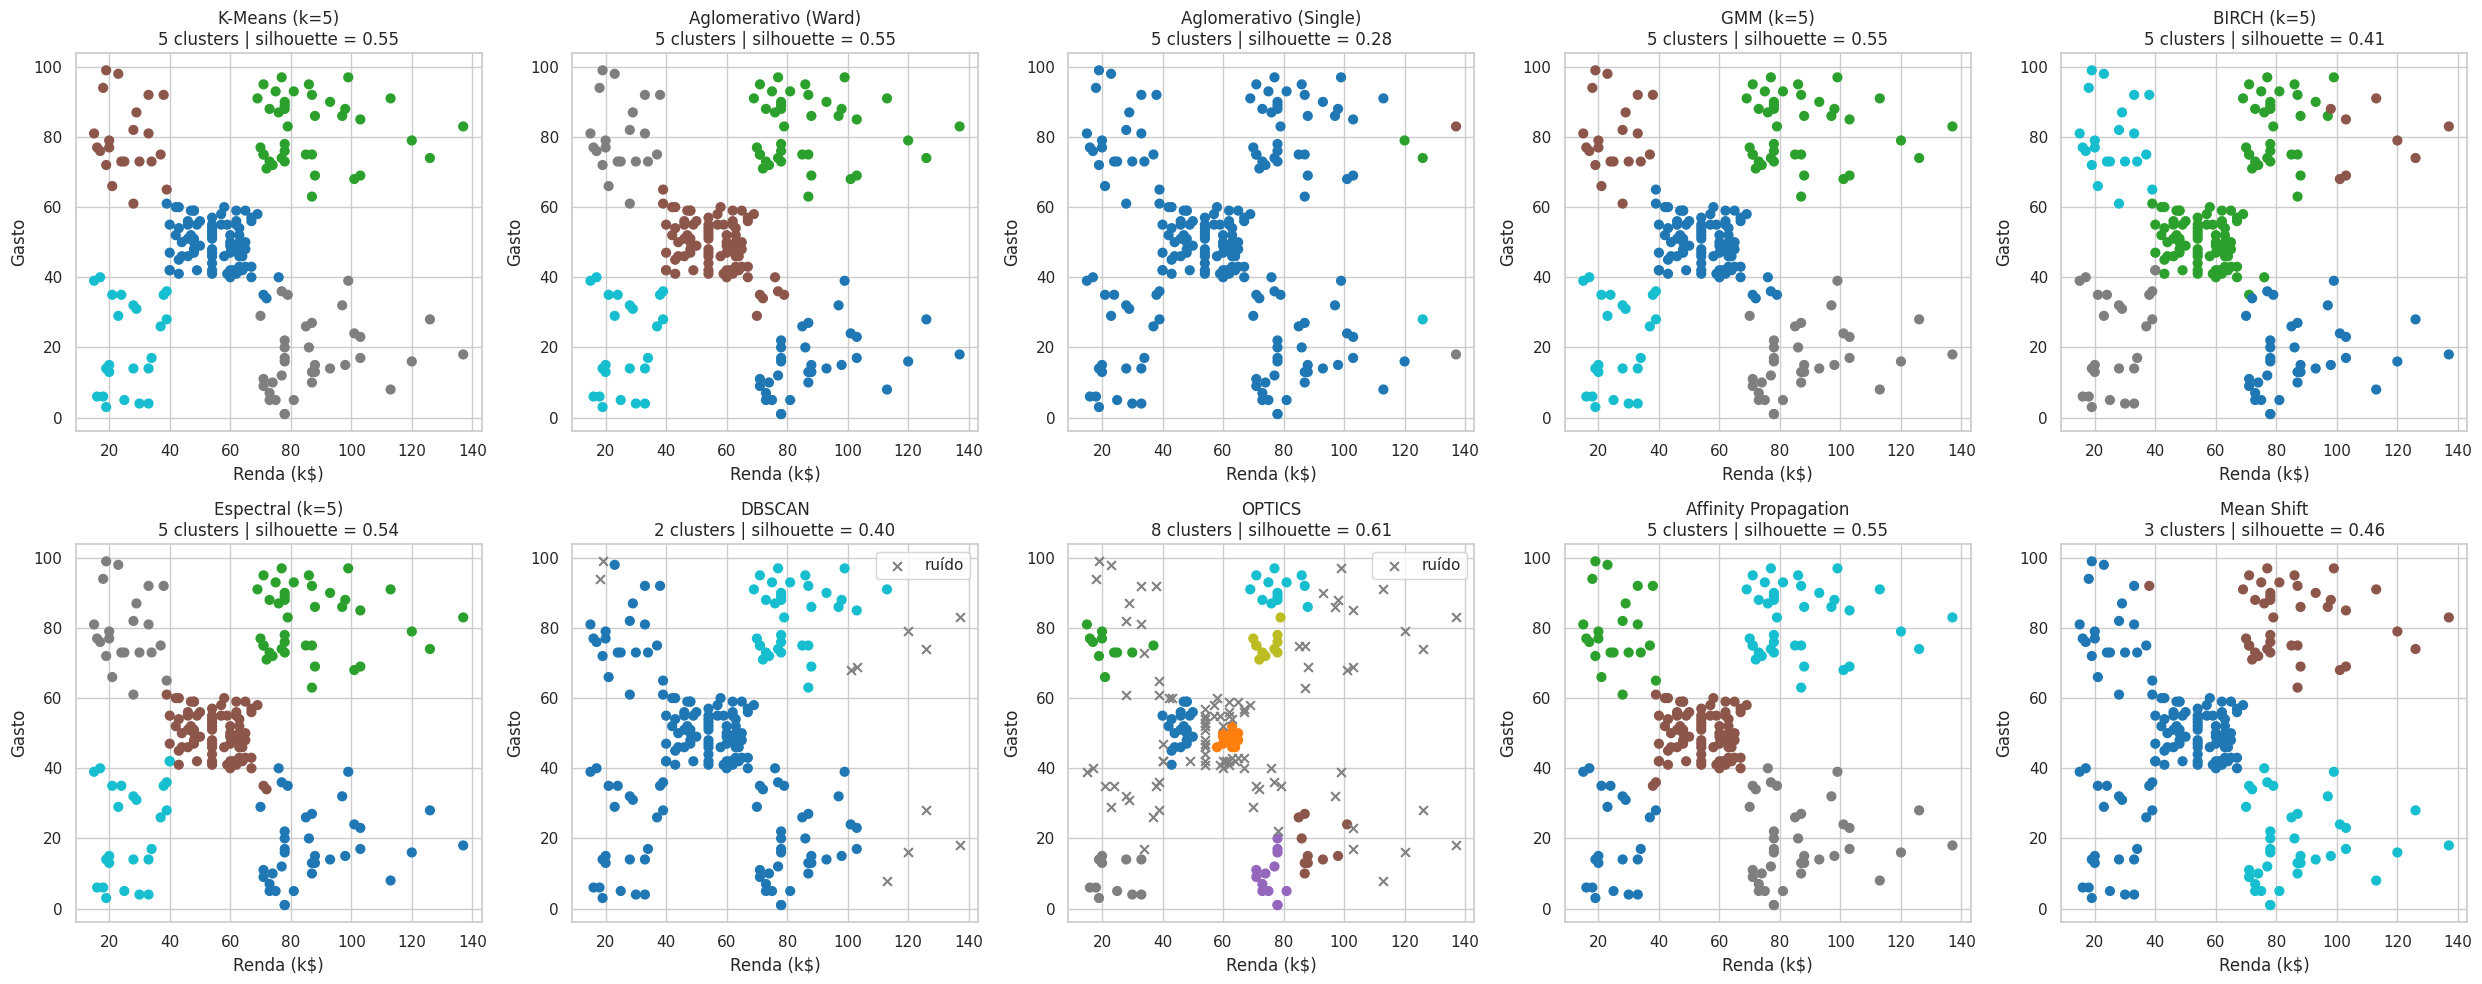

In [26]:
# Visualização lado a lado (coordenadas originais para facilitar a leitura)
n = len(labels_modelos)
fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(5 * ((n + 1) // 2), 10))
for ax, (nome, lab) in zip(axes.ravel(), labels_modelos.items()):
    ruido = lab == -1
    ax.scatter(X[~ruido, 0], X[~ruido, 1], c=lab[~ruido], cmap='tab10', s=40)
    if ruido.any():
        ax.scatter(X[ruido, 0], X[ruido, 1], c='gray', marker='x', s=40, label='ruído')
        ax.legend()
    sil = tabela.loc[nome, 'Silhouette']
    ax.set_title(f"{nome}\n{tabela.loc[nome, 'Clusters']} clusters | silhouette = {sil:.2f}" if not np.isnan(sil) else f"{nome}\n{tabela.loc[nome, 'Clusters']} clusters")
    ax.set_xlabel('Renda (k$)'); ax.set_ylabel('Gasto')
for ax in axes.ravel()[n:]:
    ax.axis('off')
plt.tight_layout()
plt.show()

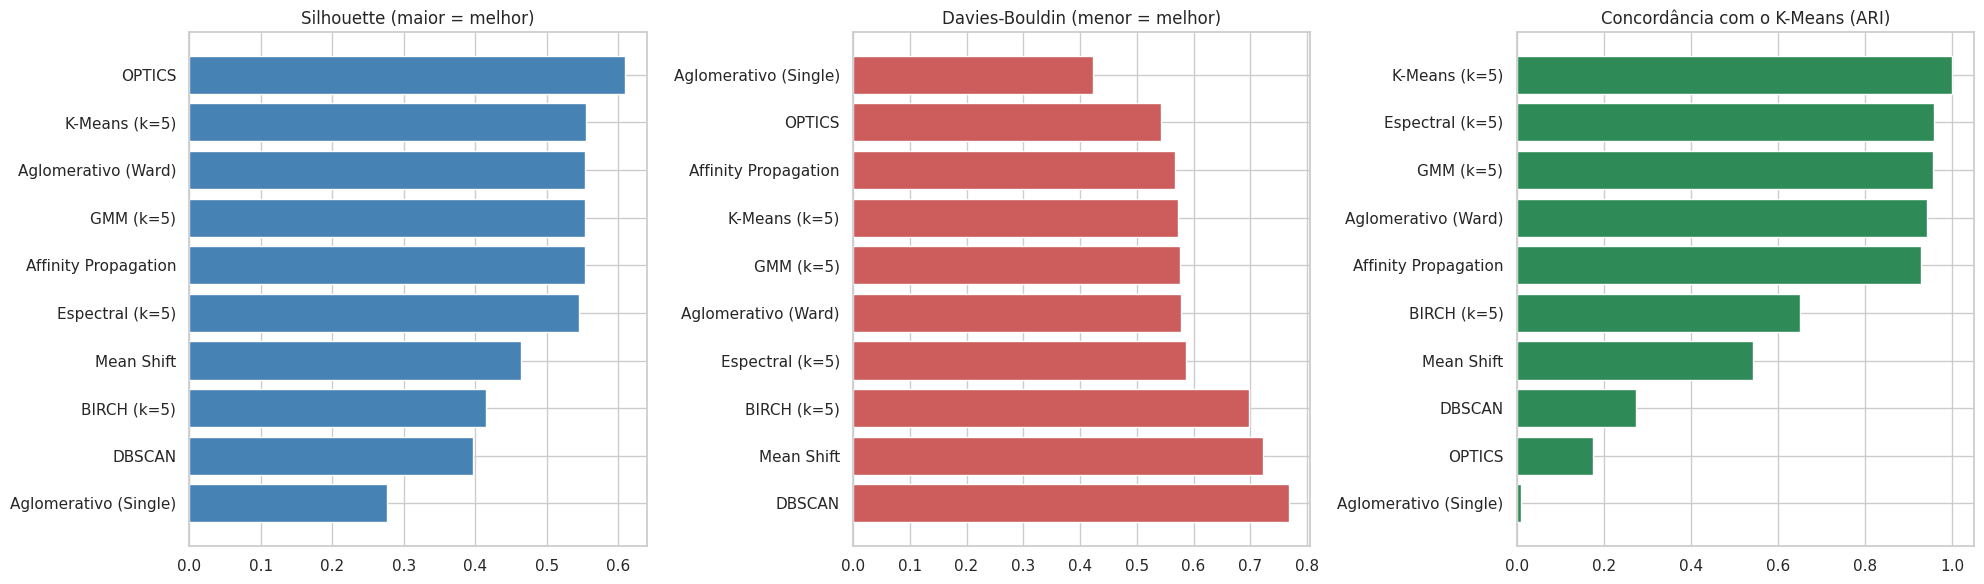

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
t = tabela.sort_values('Silhouette')
axes[0].barh(t.index, t['Silhouette'].fillna(0), color='steelblue')
axes[0].set_title('Silhouette (maior = melhor)')
t = tabela.sort_values('Davies-Bouldin', ascending=False)
axes[1].barh(t.index, t['Davies-Bouldin'].fillna(0), color='indianred')
axes[1].set_title('Davies-Bouldin (menor = melhor)')
t = tabela.sort_values('ARI vs K-Means')
axes[2].barh(t.index, t['ARI vs K-Means'], color='seagreen')
axes[2].set_title('Concordância com o K-Means (ARI)')
plt.tight_layout()
plt.show()

### 9.3 Análises complementares dos modelos

**Dendrograma (clustering hierárquico, Ward):** mostra a ordem em que os grupos são fundidos. A linha vermelha corta a árvore em 5 clusters; saltos grandes de altura indicam que a fusão junta grupos muito diferentes.

**GMM - critério BIC:** o BIC penaliza modelos complexos; o menor valor indica o melhor número de componentes e o melhor tipo de covariância.

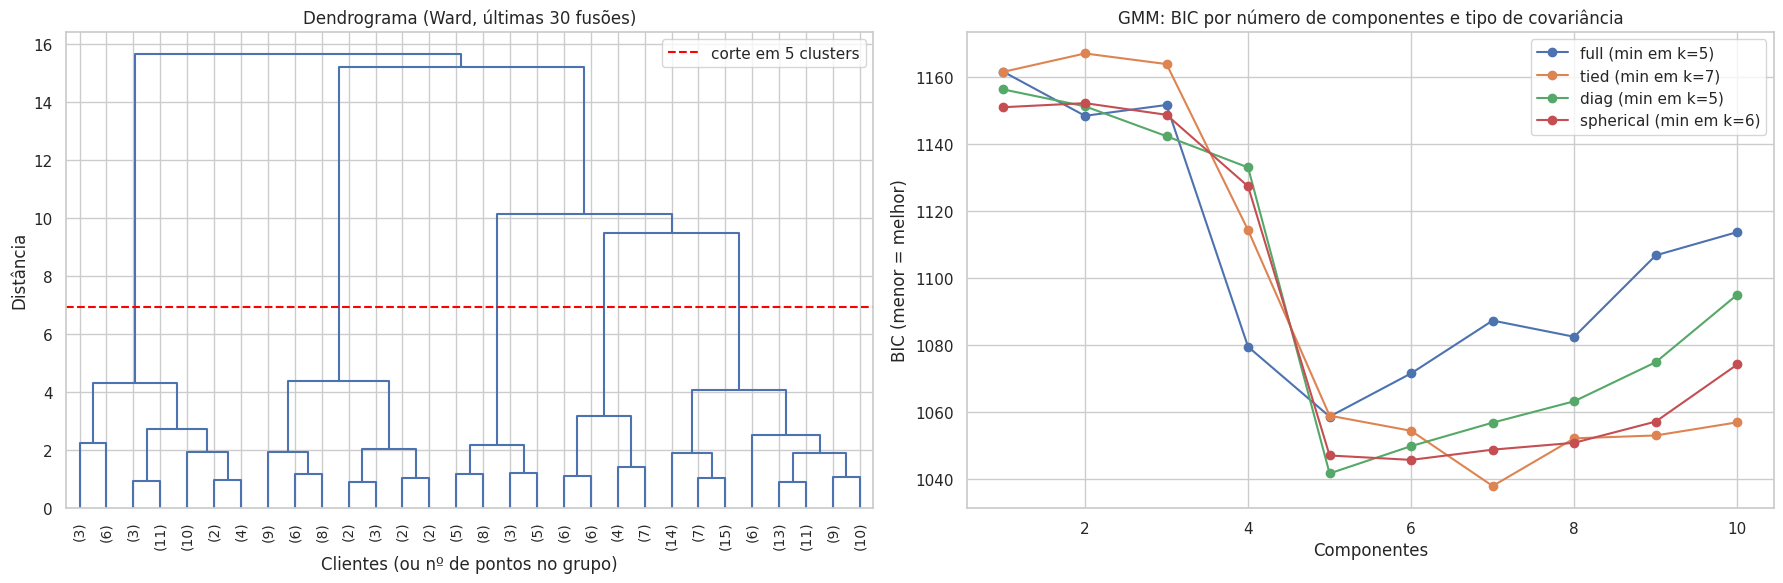

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

Z = linkage(X_s, method='ward')
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, ax=axes[0], color_threshold=0)
corte = (Z[-5, 2] + Z[-4, 2]) / 2
axes[0].axhline(corte, color='red', ls='--', label='corte em 5 clusters')
axes[0].set_title('Dendrograma (Ward, últimas 30 fusões)')
axes[0].set_xlabel('Clientes (ou nº de pontos no grupo)'); axes[0].set_ylabel('Distância')
axes[0].legend()

for cov in ['full', 'tied', 'diag', 'spherical']:
    bics = [GaussianMixture(k, covariance_type=cov, n_init=3, random_state=SEED).fit(X_s).bic(X_s)
            for k in range(1, 11)]
    axes[1].plot(range(1, 11), bics, 'o-', label=f'{cov} (min em k={int(np.argmin(bics)) + 1})')
axes[1].set_title('GMM: BIC por número de componentes e tipo de covariância')
axes[1].set_xlabel('Componentes'); axes[1].set_ylabel('BIC (menor = melhor)')
axes[1].legend()
plt.tight_layout()
plt.show()

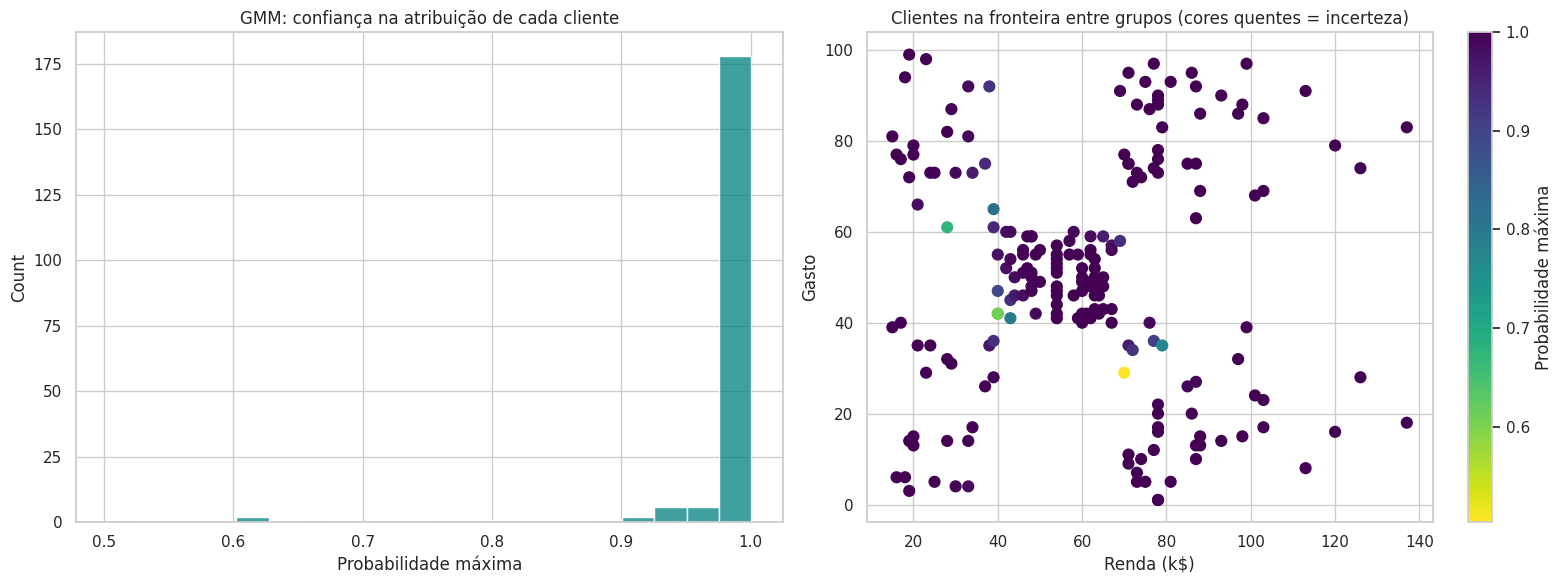

Clientes com confiança < 90%: 8 de 200


In [29]:
# Incerteza do GMM: probabilidade de pertencer ao cluster atribuído (clustering "suave")
gmm = modelos['GMM (k=5)']
prob_max = gmm.predict_proba(X_s).max(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.histplot(prob_max, bins=20, ax=axes[0], color='teal')
axes[0].set_title('GMM: confiança na atribuição de cada cliente')
axes[0].set_xlabel('Probabilidade máxima')
sc = axes[1].scatter(X[:, 0], X[:, 1], c=prob_max, cmap='viridis_r', s=60)
plt.colorbar(sc, ax=axes[1], label='Probabilidade máxima')
axes[1].set_title('Clientes na fronteira entre grupos (cores quentes = incerteza)')
axes[1].set_xlabel('Renda (k$)'); axes[1].set_ylabel('Gasto')
plt.tight_layout()
plt.show()
print(f"Clientes com confiança < 90%: {(prob_max < 0.9).sum()} de {len(prob_max)}")

### 9.4 Discussão: qual modelo escolher?

| Modelo | Pontos fortes | Limitações neste problema |
|---|---|---|
| **K-Means** | Simples, rápido, centroides interpretáveis; ideal para grupos compactos e arredondados (como aqui) | Exige definir $K$; sensível a outliers; todo ponto é atribuído a um grupo |
| **Aglomerativo (Ward)** | Não depende de inicialização; o dendrograma mostra a hierarquia | Custo $O(n^2)$; sem como "desfazer" fusões; o *single linkage* sofre do efeito cadeia e cria grupos minúsculos |
| **GMM** | Clusters elípticos e probabilidades de pertencimento | Mais parâmetros; só traz ganho se os grupos não forem esféricos |
| **DBSCAN / OPTICS** | Encontram formas arbitrárias e **detectam ruído** | Sensíveis a `eps`/`min_samples`; com densidades diferentes tendem a agrupar demais ou marcar muito ruído |
| **Affinity Propagation** | Não exige $K$ | Muito sensível a `preference`; custo $O(n^2)$ em memória |
| **Mean Shift** | Não exige $K$; acha as modas de densidade | Sensível à `bandwidth` |
| **BIRCH / Espectral** | BIRCH escala bem; espectral lida com formas complexas | Ganho pequeno em dados que já são bem separados |

**Conclusão da comparação:** como os dados formam ilhas compactas e bem separadas no plano Renda × Gasto, os modelos baseados em centroides/gaussianas (K-Means, Ward, GMM, BIRCH, Espectral) tendem a chegar a partições muito parecidas (ARI alto). Os modelos de densidade e passagem de mensagens dependem mais de hiperparâmetros. O **K-Means é a melhor relação entre desempenho, simplicidade e interpretabilidade** para este dataset, razão pela qual o mantemos como modelo base.

## 10. K-Means com mais variáveis (idade) e estabilidade

### 10.1 Incluindo `Age`

Até aqui usamos só Renda × Gasto. Ao acrescentar **Idade** (3 variáveis padronizadas) podemos descobrir segmentos que dependem da faixa etária. Escolhemos $K$ por silhouette entre 3 e 8 (valores menores como $K=2$ costumam ganhar silhouette, mas são pouco úteis para o negócio).

,WCSS,Silhouette,Calinski-Harabasz,Davies-Bouldin
k,,,,
3,295.212,0.358,101.695,1.050
4,205.225,0.404,125.676,0.931
5,168.248,0.417,125.101,0.875
6,133.868,0.428,135.102,0.825
7,117.012,0.417,132.774,0.793
8,103.873,0.408,131.006,0.892


K escolhido para o modelo estendido (maior silhouette em 3..8): 6
ARI entre o K-Means base (Renda+Gasto) e o estendido (+Idade): 0.700


,Age,Annual Income (k$),Spending Score (1-100),Clientes,% Mulheres
Cluster_Ext,,,,,
0,56.3,54.3,49.1,45,57.8
1,26.8,57.1,48.1,39,64.1
2,41.9,88.9,17.0,33,42.4
3,32.7,86.5,82.1,39,53.8
4,25.0,25.3,77.6,23,56.5
5,45.5,26.3,19.4,21,61.9


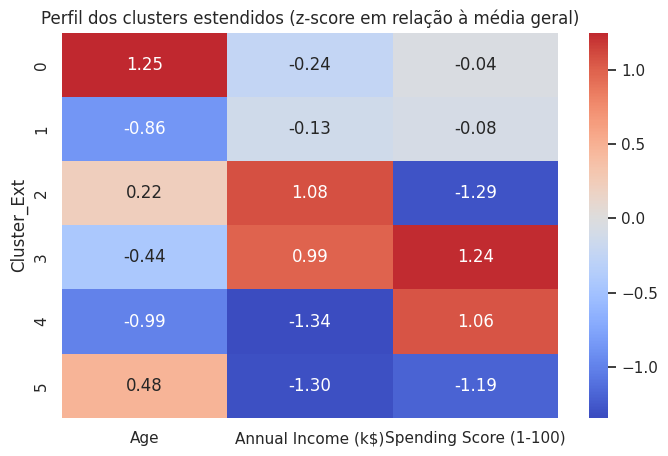

In [30]:
cols_ext = ['Age', COL_INC, COL_SPEND]
Xe = X_scaled['Estendido (+Idade)']
res_e = avaliar_k(Xe, range(3, 9))
display(res_e.round(3))
k_ext = int(res_e['Silhouette'].idxmax())
print(f"K escolhido para o modelo estendido (maior silhouette em 3..8): {k_ext}")

km_ext = KMeans(n_clusters=k_ext, n_init=10, random_state=SEED).fit(Xe)
df['Cluster_Ext'] = km_ext.labels_
print(f"ARI entre o K-Means base (Renda+Gasto) e o estendido (+Idade): {adjusted_rand_score(df['Cluster'], df['Cluster_Ext']):.3f}")

# Perfil médio (em z-score) de cada cluster do modelo estendido
perfil_ext = df.groupby('Cluster_Ext')[cols_ext].mean()
perfil_ext['Clientes'] = df['Cluster_Ext'].value_counts().sort_index()
perfil_ext['% Mulheres'] = df.groupby('Cluster_Ext')['Gender'].apply(lambda s: (s == 'Female').mean() * 100)
display(perfil_ext.round(1))

z = (df.groupby('Cluster_Ext')[cols_ext].mean() - df[cols_ext].mean()) / df[cols_ext].std()
plt.figure(figsize=(8, 5))
sns.heatmap(z, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Perfil dos clusters estendidos (z-score em relação à média geral)')
plt.show()

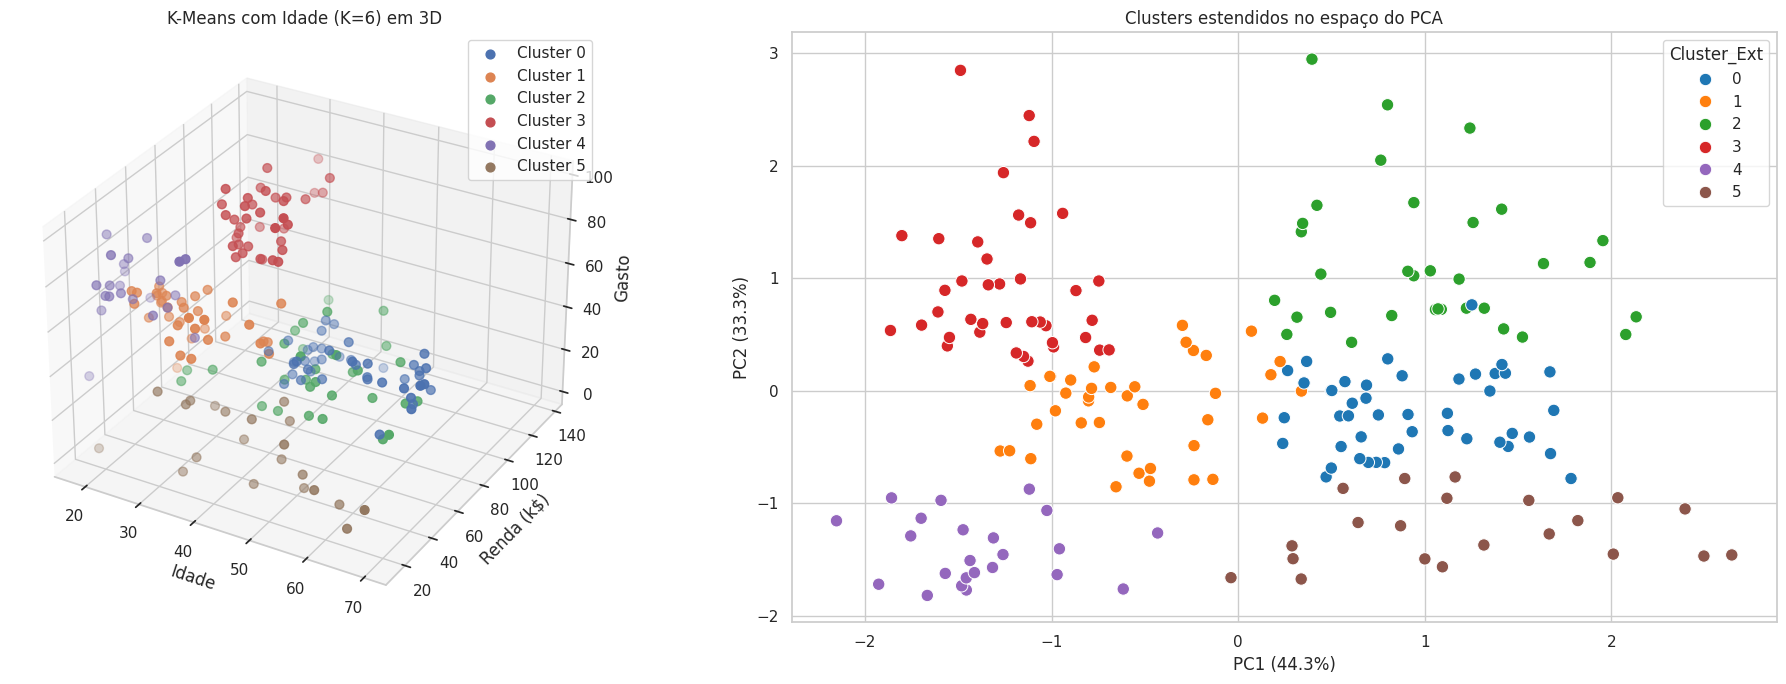

In [31]:
fig = plt.figure(figsize=(20, 7))

# 3D
ax = fig.add_subplot(1, 2, 1, projection='3d')
for c in range(k_ext):
    m = df['Cluster_Ext'] == c
    ax.scatter(df.loc[m, 'Age'], df.loc[m, COL_INC], df.loc[m, COL_SPEND], s=40, label=f'Cluster {c}')
ax.set_xlabel('Idade'); ax.set_ylabel('Renda (k$)'); ax.set_zlabel('Gasto')
ax.set_title(f'K-Means com Idade (K={k_ext}) em 3D')
ax.legend()

# PCA das 3 variáveis
pca3 = PCA(n_components=2, random_state=SEED)
P = pca3.fit_transform(Xe)
ax2 = fig.add_subplot(1, 2, 2)
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=df['Cluster_Ext'], palette='tab10', s=80, ax=ax2)
ax2.set_xlabel(f'PC1 ({pca3.explained_variance_ratio_[0]*100:.1f}%)')
ax2.set_ylabel(f'PC2 ({pca3.explained_variance_ratio_[1]*100:.1f}%)')
ax2.set_title('Clusters estendidos no espaço do PCA')
plt.tight_layout()
plt.show()

### 10.2 Estabilidade do K-Means

O K-Means depende da inicialização aleatória e pode cair em mínimos locais. Para medir a **robustez** do agrupamento, rodamos o modelo 30 vezes com `n_init=1` e sementes diferentes e comparamos cada partição com a primeira via ARI. Valores próximos de 1 indicam solução estável (e é por isso que usamos `n_init=10` no modelo final).

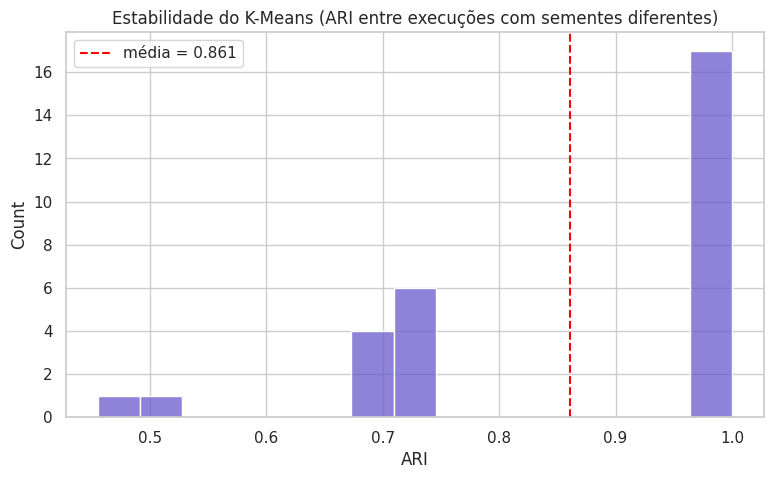

ARI mínimo: 0.455 | média: 0.861


In [32]:
labs = [KMeans(n_clusters=5, n_init=1, init='random', random_state=s).fit_predict(X) for s in range(30)]
aris = [adjusted_rand_score(labs[0], l) for l in labs[1:]]

plt.figure(figsize=(9, 5))
sns.histplot(aris, bins=15, color='slateblue')
plt.axvline(np.mean(aris), color='red', ls='--', label=f'média = {np.mean(aris):.3f}')
plt.title('Estabilidade do K-Means (ARI entre execuções com sementes diferentes)')
plt.xlabel('ARI'); plt.legend(); plt.show()
print(f"ARI mínimo: {np.min(aris):.3f} | média: {np.mean(aris):.3f}")

## 11. Conclusões da Análise (EDA + Clusterização)

**Sobre os dados (EDA)**
* O dataset tem 200 clientes e **nenhum valor ausente ou duplicado**; mesmo assim deixamos um pipeline de imputação testado (mediana vs KNN).
* Renda e Spending Score **não são correlacionados**; a única relação linear relevante é a negativa entre **Idade e Gasto**. Gênero tem pouca influência.
* Por não haver redundância, o PCA não reduz muito a dimensionalidade e serve mais para **visualização**.

**Sobre os modelos**
* Cotovelo, silhouette, Calinski-Harabasz e Davies-Bouldin apontam $K=5$ para o espaço Renda × Gasto.
* Modelos de famílias diferentes (hierárquico, GMM, BIRCH, espectral) chegam a partições semelhantes, o que reforça que **a estrutura de 5 grupos existe nos dados** e não é artefato do K-Means. Os de densidade e passagem de mensagens dependem mais dos hiperparâmetros.
* O K-Means é estável entre inicializações quando usamos `n_init=10`.

**Perfis de clientes identificados (K-Means, K=5)**
1. **Alta renda / Alto gasto (Alvo premium):** clientes mais valiosos; campanhas de produtos premium e fidelização.
2. **Alta renda / Baixo gasto (Cuidadosos):** potencial não aproveitado; promoções de custo-benefício.
3. **Baixa renda / Alto gasto (Impulsivos):** gastam acima da renda; parcelamento e campanhas de tendência.
4. **Baixa renda / Baixo gasto (Conservadores):** sensíveis a preço; cupons e descontos.
5. **Renda média / Gasto médio (massa):** público geral do shopping.

**Limitações e próximos passos**
* Spending Score é uma nota atribuída pelo shopping e não o gasto real em R$/US$; com dados transacionais (frequência, ticket médio, recência) a segmentação seria mais precisa (modelo RFM).
* Com 200 clientes, resultados de Idade e Gênero são mais sensíveis a ruído; vale validar com mais dados.
* Podemos testar outros espaços de variáveis (ex.: `Gap_pct`, `Spend_to_Income`) e acompanhar a migração de clientes entre grupos ao longo do tempo.

Este tipo de IA não supervisionada nos permite gerar *insights* de negócio valiosos a partir de dados brutos, agrupando elementos com características semelhantes sem a necessidade de intervenção humana prévia.

In [33]:
# Exporta a base com os clusters e perfis
saida = df[['CustomerID', 'Gender', 'Age', COL_INC, COL_SPEND, 'Cluster', 'Perfil', 'Cluster_Ext']]
saida.to_csv('mall_customers_clusterizado.csv', index=False)
display(saida.head(10))
try:
    from google.colab import files
    files.download('mall_customers_clusterizado.csv')   # baixa o CSV no Colab
except ImportError:
    pass

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster,Perfil,Cluster_Ext
0,1,Male,19,15,39,4,Conservadores,4
1,2,Male,21,15,81,2,Impulsivos,4
2,3,Female,20,16,6,4,Conservadores,5
3,4,Female,23,16,77,2,Impulsivos,4
4,5,Female,31,17,40,4,Conservadores,5
5,6,Female,22,17,76,2,Impulsivos,4
6,7,Female,35,18,6,4,Conservadores,5
7,8,Female,23,18,94,2,Impulsivos,4
8,9,Male,64,19,3,4,Conservadores,5
9,10,Female,30,19,72,2,Impulsivos,4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>